# NHẬN DẠNG CHỮ TRONG ẢNH BẰNG CRNN + BiLSTM + CTC (tiếng Việt có dấu + tiếng Anh)
**Notebook hoàn chỉnh, Giai đoạn 1 → 7, chạy trên Google Colab (GPU T4).**

| Giai đoạn | Nội dung |
|---|---|
| 1 | Môi trường, sinh dataset (Pillow, font Unicode, NFC, chống rò rỉ dữ liệu) |
| 2 | Tiền xử lý: grayscale, resize giữ tỷ lệ, padding, chuẩn hóa, augmentation |
| 3 | Vocabulary, CNN, BiLSTM, CRNN hoàn chỉnh, kiểm tra kích thước tensor |
| 4 | CTC Loss, kiểm tra điều kiện CTC, Greedy + Beam Search decoder, unit test |
| 5 | Huấn luyện, checkpoint, resume, early stopping, đường cong loss |
| 6 | Đánh giá CER, Word Accuracy; kiểm thử ảnh thực tế; upload ảnh |
| 7 | Phân tích lỗi, hạn chế, hướng phát triển, báo cáo tự động |

### Cách chạy
1. Chọn **Runtime → Change runtime type → T4 GPU**.
2. Đặt `MODE` ở **Cell 1.3** (`"small"` để thử, `"full"` cho kết quả tốt hơn). Đây là nơi duy nhất cần đặt `MODE`.
3. Chạy **Run all** (hoặc chạy lần lượt các cell). Chạy lại sau này: dataset được khôi phục từ Google Drive, và nếu checkpoint đã hoàn tất thì bước huấn luyện tự bỏ qua.
4. Muốn huấn luyện lại từ đầu (đổi số epoch hay cách sinh dữ liệu): đổi `DATA_TAG` ở Cell 1.3 (nếu đổi dữ liệu) hoặc `RUN_NAME` ở Cell 2.0.

Mọi số liệu trong bảng kết quả đều do notebook tính từ tập test, không nhập tay.

---
# GIAI ĐOẠN 1: Môi trường và Dataset

**Mục tiêu giai đoạn này:** thiết lập Colab, tạo bộ dữ liệu ảnh chữ tiếng Việt có dấu (train/val/test), kiểm tra chất lượng dữ liệu.

**Quyết định thiết kế (cần ghi vào báo cáo):**
- `TextRecognitionDataGenerator` (TRDG) đã ngừng bảo trì và phụ thuộc phiên bản Pillow cũ, dễ xung đột với Colab hiện tại. Vì vậy dùng **bộ sinh ảnh tự viết bằng Pillow** (đúng phương án dự phòng của đề bài): ổn định, kiểm soát được font Unicode và augmentation.
- Chỉ dùng font **có đủ glyph tiếng Việt** (kiểm tra bằng `fontTools`, không đoán).
- Chia tập theo **nội dung văn bản** (mỗi văn bản chỉ xuất hiện ở đúng 1 tập, kể cả khác hoa/thường hoặc dấu câu) để không rò rỉ dữ liệu.
- Mọi nhãn được chuẩn hóa **Unicode NFC**.
- Kho văn bản gồm tiếng Việt **và tiếng Anh**, có nhóm chữ in hoa (viết tắt, dãy `ABC...`, cụm viết hoa toàn bộ).
- Dataset sinh ở `/content` (nhanh), nén 1 file `.zip` lưu vào Google Drive. Lần chạy sau tự giải nén, không sinh lại.

### Cell 1.1: Kiểm tra Python, PyTorch, GPU và mount Google Drive

In [ ]:
import sys
print("Python:", sys.version.split()[0])

import torch, torchvision
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("Không có GPU. Vào Runtime > Change runtime type > T4 GPU (giai đoạn dataset vẫn chạy được trên CPU).")
print("Device:", DEVICE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("IN_COLAB:", IN_COLAB)

Python: 3.13.16
PyTorch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 15.6 GB
Device: cuda
Mounted at /content/drive
IN_COLAB: True


### Cell 1.2: Cài đặt thư viện và font Unicode
Colab đã có sẵn torch, numpy, pandas, matplotlib, OpenCV, Pillow, tqdm. Chỉ cài thêm `jiwer` (tính CER ở giai đoạn sau), `fonttools` (kiểm tra glyph) và các font có tiếng Việt.

In [ ]:
!pip install -q jiwer fonttools
!apt-get -qq update > /dev/null 2>&1
!apt-get -qq install -y fonts-noto-core fonts-dejavu-core fonts-liberation fonts-freefont-ttf > /dev/null 2>&1
print("Cài đặt xong.")

Cài đặt xong.


### Cell 1.3: Cấu hình dự án
**`MODE` này áp dụng cho toàn bộ notebook.** Đổi `MODE` thành `"full"` khi muốn dataset đầy đủ (15.000 / 2.500 / 2.500). Nên chạy `"small"` trước để kiểm tra pipeline.

In [ ]:
import json, random, string, unicodedata, zipfile, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import matplotlib.pyplot as plt

SEED = 42
MODE = "small"          # "small" (chạy thử) hoặc "full"
CONFIGS = {
    "small": dict(train=2000,  val=400,  test=400),
    "full":  dict(train=15000, val=2500, test=2500),
}
N_SPLIT = CONFIGS[MODE]
MAX_LEN = 40            # độ dài tối đa của 1 nhãn (ký tự) để ảnh không quá rộng

LOCAL_ROOT   = Path("/content") if IN_COLAB else Path(".")
PROJECT_ROOT = Path("/content/drive/MyDrive/OCR_CRNN") if IN_COLAB else Path("./OCR_CRNN")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

DATA_TAG  = f"{MODE}_en"          # đổi thẻ này khi thay đổi cách sinh dữ liệu, để không dùng nhầm zip cũ
DATA_ROOT = LOCAL_ROOT / f"dataset_{DATA_TAG}"
DATA_ZIP  = PROJECT_ROOT / f"dataset_{DATA_TAG}.zip"
print("MODE:", MODE, N_SPLIT)
print("Dataset cục bộ :", DATA_ROOT)
print("Zip trên Drive :", DATA_ZIP)

random.seed(SEED); np.random.seed(SEED)

MODE: small {'train': 2000, 'val': 400, 'test': 400}
Dataset cục bộ : /content/dataset_small_en
Zip trên Drive : /content/drive/MyDrive/OCR_CRNN/dataset_small_en.zip


### Cell 1.4: Bộ ký tự (charset)
Gồm chữ cái không dấu (a-z, A-Z), toàn bộ chữ tiếng Việt có dấu (hoa + thường), chữ số, dấu cách và dấu câu. Ký tự BLANK của CTC sẽ được thêm ở Giai đoạn 3.

In [ ]:
VN_ACCENT_LOWER = "àáảãạăằắẳẵặâầấẩẫậđèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵ"
VN_ACCENT_UPPER = VN_ACCENT_LOWER.upper()
PUNCT  = " .,:;!?-()/%'\"&+@#"
CHARSET = "".join(sorted(set(string.ascii_letters + VN_ACCENT_LOWER + VN_ACCENT_UPPER + string.digits + PUNCT)))

# Mỗi ký tự phải là 1 code point NFC duy nhất
assert all(unicodedata.is_normalized("NFC", c) and len(c) == 1 for c in CHARSET)
print("Số ký tự:", len(CHARSET))
print(repr(CHARSET))

def normalize_text(t: str) -> str:
    return unicodedata.normalize("NFC", t).strip()

TONED_VOWELS = ["aàáảãạ", "ăằắẳẵặ", "âầấẩẫậ", "eèéẻẽẹ", "êềếểễệ", "iìíỉĩị",
                "oòóỏõọ", "ôồốổỗộ", "ơờớởỡợ", "uùúủũụ", "ưừứửữự", "yỳýỷỹỵ"]

Số ký tự: 214
' !"#%&\'()+,-./0123456789:;?@ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÀÁÂÃÈÉÊÌÍÒÓÔÕÙÚÝàáâãèéêìíòóôõùúýĂăĐđĨĩŨũƠơƯưẠạẢảẤấẦầẨẩẪẫẬậẮắẰằẲẳẴẵẶặẸẹẺẻẼẽẾếỀềỂểỄễỆệỈỉỊịỌọỎỏỐốỒồỔổỖỗỘộỚớỜờỞởỠỡỢợỤụỦủỨứỪừỬửỮữỰựỲỳỴỵỶỷỸỹ'


### Cell 1.5: Tìm font có đủ glyph tiếng Việt
Kiểm tra bảng `cmap` của từng font: font nào thiếu bất kỳ ký tự nào trong `CHARSET` sẽ bị loại (tránh ô vuông/tofu làm sai nhãn).

In [ ]:
import subprocess, glob
from fontTools.ttLib import TTFont

def list_font_files():
    paths = set()
    try:
        out = subprocess.run(["fc-list", ":lang=vi", "file"], capture_output=True, text=True).stdout
        for line in out.splitlines():
            p = line.split(": ")[0].strip().rstrip(":")
            if p.lower().endswith((".ttf", ".otf")):
                paths.add(p)
    except FileNotFoundError:
        pass
    for root in ["/usr/share/fonts", "/usr/local/share/fonts"]:
        for ext in ("ttf", "otf"):
            paths.update(glob.glob(f"{root}/**/*.{ext}", recursive=True))
    return sorted(paths)

def font_supports_charset(path):
    try:
        f = TTFont(path, lazy=True)
        cmap = f.getBestCmap()
        ok = cmap is not None and all(ord(c) in cmap for c in CHARSET)
        f.close()
        if not ok:
            return False
        ImageFont.truetype(path, 32).getbbox("Việt Ậ")   # đảm bảo Pillow mở được
        return True
    except Exception:
        return False

FONTS = [p for p in list_font_files() if font_supports_charset(p)]
print(f"Font hợp lệ: {len(FONTS)}")
for p in FONTS[:15]:
    print("  ", Path(p).name)
assert len(FONTS) >= 3, "Quá ít font có tiếng Việt. Hãy chạy lại Cell 1.2 (cài font)."

Font hợp lệ: 47
   DejaVuSans-Bold.ttf
   DejaVuSans.ttf
   DejaVuSerif-Bold.ttf
   DejaVuSerif.ttf
   FreeMono.ttf
   FreeMonoBold.ttf
   FreeMonoBoldOblique.ttf
   FreeMonoOblique.ttf
   FreeSans.ttf
   FreeSansBold.ttf
   FreeSansBoldOblique.ttf
   FreeSansOblique.ttf
   FreeSerif.ttf
   FreeSerifBold.ttf
   FreeSerifBoldItalic.ttf


### Cell 1.6: Tạo kho văn bản (corpus)
Sinh văn bản đa dạng: cụm từ tiếng Việt, từ đơn, số/ngày/điện thoại, chuỗi chữ-số, nhóm nguyên âm có đủ 5 thanh, chuỗi ký tự dễ nhầm (`0 O o 1 l I 5 S 8 B`). Mỗi văn bản được khử trùng theo khóa `casefold` + bỏ dấu câu cuối, sau đó **chia tập theo văn bản**, nên không có nội dung nào nằm ở 2 tập.

In [ ]:
SYLLABLES = unicodedata.normalize("NFC", '''
xin chào việt nam trí tuệ nhân tạo học máy sâu nhận dạng chữ trong ảnh công nghệ thông tin
trường đại học mô hình mạng nơ-ron tích chập xử lý ngôn ngữ tự nhiên người những được không
với cho của một các trên này có đã sẽ đang cũng như khi để từ về năm tháng ngày giờ phút
hôm nay mai qua sáng trưa chiều tối đêm nhà lớp thầy cô bạn em anh chị mẹ bố con gia đình
sinh viên giáo bài tập thi điểm kiến thức khoa toán văn lý hóa sử địa tiếng thành phố
hà nội huế đà nẵng hải phòng cần thơ bắc ninh sông núi biển rừng cây hoa lá quả mưa nắng
gió mây trời đất nước lửa xe đường phố chợ cửa hàng sách báo bút vở bàn ghế máy tính điện
thoại phần mềm dữ liệu thuật toán hệ thống ảnh hình số ký tự văn bản dấu thanh huyền sắc
hỏi ngã nặng đẹp tốt xấu lớn nhỏ cao thấp dài ngắn nhanh chậm mới cũ vui buồn yêu thương
nhớ quên đi đến ăn uống ngủ làm nghỉ đọc viết nói nghe nhìn thấy biết hiểu nghĩ muốn cần
phải thể rất hơn nhất nhiều ít tất cả mọi mỗi hai ba bốn sáu bảy tám chín mười trăm nghìn
triệu quốc gia dân tộc lịch sử văn hóa kinh tế xã hội giáo dục y tế môi trường năng lượng
thị trường doanh nghiệp sản phẩm dịch vụ khách hàng chất lượng an toàn phát triển bền vững
nghiên cứu thực nghiệm kết quả đánh giá phân tích thiết kế xây dựng triển khai ứng dụng
kỹ thuật sinh học vật chất ánh sáng âm thanh chuyển động tốc độ khoảng cách thời gian
tương lai hiện tại quá khứ hạnh phúc bình yên tự do hòa bình tình bạn ước mơ cố gắng
chăm chỉ kiên trì thành công thử thách cơ hội lựa chọn quyết định trách nhiệm tôn trọng
ngoại ngữ hội thảo hợp tác giao lưu chương trình khóa luận đồ án báo cáo tốt nghiệp
''').split()
SYLLABLES = sorted({normalize_text(s) for s in SYLLABLES if all(c in CHARSET for c in normalize_text(s))})
print("Số âm tiết/từ gốc:", len(SYLLABLES))

ENGLISH = '''
water window fresh forest kitchen jacket wonder fifty flower yellow zebra zero jazz jungle journey judge juice
quiet queen question quarter xylophone mix six taxi expert extra example fix wax zoo zone size dozen puzzle crazy
frozen fabric factory family famous farmer father feather fiction finger fire fish flag floor flight follow food foot
force forget friend front fruit funny future garden gentle giant glass globe gold grass green group guitar hammer happy
heart heavy honey horse house human hunter island jewel jelly job join joke joy keep kettle key kind king kiss knee
knife knock know lake lamp large laugh learn leaf left lemon letter light line lion list little local lock long love
lucky machine magic market master memory metal middle milk mirror money moon morning mountain music napkin nature
needle night noble north novel number ocean office orange paper parent people pencil pepper pilot pizza planet pocket
power quality rabbit river rocket school science screen season shadow silver simple sister sky snow soft spring storm
summer sun table teacher thunder ticket tiger tower train travel tree uncle unique valley village voice walk wall warm
wave week west wheel white wild wind winter wise wolf world write year young zipper
'''.split()

FIXED_PHRASES = [normalize_text(s) for s in [
    "Xin chào Việt Nam", "Trí tuệ nhân tạo", "Học máy và học sâu", "Nhận dạng chữ trong ảnh",
    "Công nghệ thông tin", "Trường Đại học Phenikaa", "Mô hình mạng nơ-ron tích chập",
    "Xử lý ngôn ngữ tự nhiên", "Cộng hòa xã hội chủ nghĩa Việt Nam", "Độc lập - Tự do - Hạnh phúc",
]]
ASCII_NAMES = ["nguyen", "tran", "le", "pham", "hoang", "vu", "dang", "bui", "do", "ngo"]
CONFUSABLE = "0O1lI5S2Z8B6G"
NON_SPACE_CHARS = [c for c in CHARSET if c != " "]

def dig(r, k): return "".join(r.choice(string.digits) for _ in range(k))

def case_variant(r, words):
    q = r.random()
    if q < 0.45:   words[0] = words[0].capitalize()
    elif q < 0.58: words = [w.capitalize() for w in words]
    elif q < 0.70: words = [w.upper() for w in words]
    return words

def add_punct(r, t, n):
    if r.random() < 0.10 and n >= 3:
        k = r.randint(1, n - 2); ws = t.split(" "); ws[k] += ","; t = " ".join(ws)
    if r.random() < 0.25: t += r.choice([".", "!", "?"])
    return t

def make_text(r):
    p = r.random()
    if p < 0.03:
        return r.choice(FIXED_PHRASES)
    if p < 0.08:                                   # từ đơn (Việt hoặc Anh)
        w = r.choice(SYLLABLES if r.random() < 0.5 else ENGLISH)
        return r.choice([w, w.capitalize(), w.upper()])
    if p < 0.13:                                   # số, ngày, điện thoại
        f = r.choice(["num", "date", "phone", "money", "pct"])
        if f == "num":   return dig(r, r.randint(1, 10))
        if f == "date":  return f"{r.randint(1,28):02d}/{r.randint(1,12):02d}/{r.randint(1990,2026)}"
        if f == "phone": return f"0{r.randint(3,9)}{dig(r,8)}"
        if f == "money": return f"{r.randint(1,999)}.{dig(r,3)}.{dig(r,3)}"
        return f"{r.randint(0,99)},{r.randint(0,9)}%"
    if p < 0.19:                                   # nhóm nguyên âm đủ thanh điệu
        parts = []
        for _ in range(r.randint(3, 5)):
            c = r.choice(["", "b", "c", "d", "g", "h", "k", "l", "m", "n", "t", "v", "x"])
            parts.append(c + r.choice(r.choice(TONED_VOWELS)))
        t = " ".join(parts)
        return t.upper() if r.random() < 0.5 else t
    if p < 0.24:                                   # chuỗi dễ nhầm
        return "".join(r.choice(CONFUSABLE + "oO") for _ in range(r.randint(4, 10)))
    if p < 0.29:                                   # chuỗi chữ + số
        return normalize_text(r.choice([
            f"Lớp {r.randint(1,12)}{r.choice('ABCD')}{r.randint(1,9)}",
            f"Phòng {dig(r,3)}", f"Tầng {r.randint(1,30)}",
            f"Mã SV: {r.randint(2018,2025)}{r.choice('ABCD')}{dig(r,3)}",
            f"Điểm: {r.randint(0,9)},{r.randint(0,9)}",
            f"Tel: 09{dig(r,8)}",
            f"{r.choice(ASCII_NAMES)}{dig(r,2)}@{r.choice(ASCII_NAMES)}.vn",
        ]))
    if p < 0.41:                                   # chuỗi ký tự ngẫu nhiên: đảm bảo MỌI ký tự trong vocab đều có mẫu
        n_chars = r.randint(3, 12)
        t = "".join(r.choice(NON_SPACE_CHARS) for _ in range(n_chars))
        if n_chars >= 6 and r.random() < 0.4:
            k = r.randint(2, n_chars - 2); t = t[:k] + " " + t[k:]
        return t
    if p < 0.49:                                   # CHỮ IN HOA: viết tắt, dãy bảng chữ cái, cụm tiếng Việt viết hoa
        f = r.choice(["acronym", "alpha_run", "upper_digits", "vn_upper"])
        if f == "acronym":
            return "".join(r.choice(string.ascii_uppercase) for _ in range(r.randint(2, 8)))
        if f == "alpha_run":
            L = r.randint(4, 12); st = r.randint(0, 26 - L)
            base = r.choice([string.ascii_uppercase, string.ascii_lowercase])[st:st + L]
            return " ".join(base) if r.random() < 0.3 else base
        if f == "upper_digits":
            return "".join(r.choice(string.ascii_uppercase + string.digits) for _ in range(r.randint(4, 10)))
        return " ".join(w.upper() for w in [r.choice(SYLLABLES) for _ in range(r.randint(2, 4))])
    if p < 0.65:                                   # cụm từ tiếng Anh
        n = r.randint(2, 6)
        words = case_variant(r, [r.choice(ENGLISH) for _ in range(n)])
        return add_punct(r, " ".join(words), n)
    n = r.randint(2, 6)                            # cụm từ tiếng Việt
    words = case_variant(r, [r.choice(SYLLABLES) for _ in range(n)])
    return add_punct(r, " ".join(words), n)

def dedup_key(t):
    return t.casefold().strip(" .,:;!?-")

def build_corpus(total, seed):
    r = random.Random(seed)
    seen, texts = set(), []
    attempts = 0
    while len(texts) < total and attempts < total * 100:
        attempts += 1
        t = normalize_text(make_text(r))
        if not t or len(t) > MAX_LEN or any(c not in CHARSET for c in t):
            continue
        k = dedup_key(t)
        if k in seen:
            continue
        seen.add(k); texts.append(t)
    assert len(texts) == total, f"Chỉ tạo được {len(texts)}/{total} văn bản duy nhất"
    return texts

total = N_SPLIT["train"] + N_SPLIT["val"] + N_SPLIT["test"]
ALL_TEXTS = build_corpus(total, SEED)
random.Random(SEED).shuffle(ALL_TEXTS)
SPLIT_TEXTS = {
    "test":  ALL_TEXTS[:N_SPLIT["test"]],
    "val":   ALL_TEXTS[N_SPLIT["test"]:N_SPLIT["test"] + N_SPLIT["val"]],
    "train": ALL_TEXTS[N_SPLIT["test"] + N_SPLIT["val"]:],
}
keys = {s: {dedup_key(t) for t in v} for s, v in SPLIT_TEXTS.items()}
assert not (keys["train"] & keys["val"]) and not (keys["train"] & keys["test"]) and not (keys["val"] & keys["test"])
print({s: len(v) for s, v in SPLIT_TEXTS.items()}, "-> không trùng nội dung giữa các tập")
print("Ví dụ:", ALL_TEXTS[:6])

Số âm tiết/từ gốc: 316
{'test': 400, 'val': 400, 'train': 2000} -> không trùng nội dung giữa các tập
Ví dụ: ['LO BÃ Ẵ BÀ', 'TOÁN ƯỚC', 'Parent crazy.', 'òRẹìà ƠÒứ', 'Đường Rừng.', '46902983']


### Cell 1.7: Bộ sinh ảnh (Pillow)
Mỗi ảnh có: font ngẫu nhiên, cỡ chữ 28–64, màu chữ/nền có kiểm tra độ tương phản, nghiêng nhẹ (±3°), làm mờ, đổi sáng/tương phản, nhiễu Gaussian. Mỗi ảnh dùng seed riêng nên **tái lập được**.

Kích thước ảnh mẫu: (1268, 90)


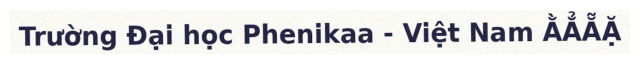

In [ ]:
def luminance(c):
    return 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]

def pick_colors(r):
    p = r.random()
    if p < 0.70:       # nền sáng, chữ tối (phổ biến nhất)
        v = r.randint(190, 255); bg = (v, min(255, v + r.randint(-15, 5)), min(255, v + r.randint(-20, 5)))
        t = r.randint(0, 90);    fg = (t, t, min(255, t + r.randint(0, 30)))
    elif p < 0.90:     # nền tối, chữ sáng
        v = r.randint(0, 60);    bg = (v, v, v + r.randint(0, 20))
        t = r.randint(190, 255); fg = (t, t, t)
    else:              # màu bất kỳ nhưng đảm bảo tương phản
        for _ in range(30):
            bg = tuple(r.randint(0, 255) for _ in range(3))
            fg = tuple(r.randint(0, 255) for _ in range(3))
            if abs(luminance(bg) - luminance(fg)) >= 110:
                break
        else:
            bg, fg = (255, 255, 255), (0, 0, 0)
    return bg, fg

def render_text_image(text, font_path, r):
    size = r.randint(28, 64)
    font = ImageFont.truetype(font_path, size)
    asc, desc = font.getmetrics()
    l, t, rr, b = font.getbbox(text)
    top = min(0, t); bottom = max(asc + desc, b)       # chiều cao theo metrics, không phụ thuộc nội dung
    text_w = max(1, rr - min(0, l))
    px, py = r.randint(4, 20), r.randint(3, 12)
    W, H = text_w + 2 * px, (bottom - top) + 2 * py
    bg, fg = pick_colors(r)
    img = Image.new("RGB", (W, H), bg)
    ImageDraw.Draw(img).text((px - min(0, l), py - top), text, font=font, fill=fg)

    if r.random() < 0.5:                                   # nghiêng nhẹ
        img = img.rotate(r.uniform(-3, 3), expand=True, fillcolor=bg, resample=Image.BICUBIC)
    if r.random() < 0.25:                                  # làm mờ
        img = img.filter(ImageFilter.GaussianBlur(r.uniform(0.5, 1.5)))
    if r.random() < 0.5:                                   # độ sáng / tương phản
        img = ImageEnhance.Brightness(img).enhance(r.uniform(0.6, 1.3))
        img = ImageEnhance.Contrast(img).enhance(r.uniform(0.6, 1.4))
    if r.random() < 0.35:                                  # nhiễu Gaussian
        arr = np.asarray(img).astype(np.float32)
        nrng = np.random.default_rng(r.randint(0, 2**31 - 1))
        arr += nrng.normal(0, r.uniform(3, 18), arr.shape)
        img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    return img

# Xem thử ngay 1 mẫu để chắc chắn glyph tiếng Việt hiển thị đúng
_r = random.Random(0)
test_img = render_text_image("Trường Đại học Phenikaa - Việt Nam ẰẲẴẶ", FONTS[0], _r)
print("Kích thước ảnh mẫu:", test_img.size)
plt.figure(figsize=(8, 1.5)); plt.imshow(test_img); plt.axis("off"); plt.show()

### Cell 1.8: Sinh dataset (hoặc khôi phục từ Drive)
Logic: (1) nếu dataset cục bộ đã đủ thì bỏ qua; (2) nếu có file zip trên Drive thì giải nén; (3) nếu không thì sinh mới rồi nén lưu lên Drive. Chế độ `small` mất khoảng 1 phút; `full` khoảng vài phút.

In [ ]:
def dataset_ready():
    return all((DATA_ROOT / s / "labels.csv").exists() for s in ["train", "val", "test"])

def build_split(name, texts, start_idx):
    img_dir = DATA_ROOT / name / "images"
    img_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for i, text in enumerate(tqdm(texts, desc=f"Sinh {name}")):
        idx = start_idx + i
        r = random.Random(SEED * 1000003 + idx)
        for attempt in range(5):                           # thử font khác nếu lỗi
            try:
                img = render_text_image(text, r.choice(FONTS), r)
                break
            except Exception as e:
                if attempt == 4:
                    raise RuntimeError(f"Không render được: {text!r}") from e
        fn = f"{idx:06d}.png"
        img.save(img_dir / fn)
        rows.append({"image_path": f"{name}/images/{fn}", "text": text})
    pd.DataFrame(rows).to_csv(DATA_ROOT / name / "labels.csv", index=False, encoding="utf-8")

t0 = time.time()
if dataset_ready():
    print("Dataset cục bộ đã tồn tại, bỏ qua bước sinh.")
elif DATA_ZIP.exists():
    print("Giải nén dataset từ Google Drive...")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DATA_ZIP) as z:
        z.extractall(DATA_ROOT)
    assert dataset_ready(), "Zip trên Drive bị thiếu file, hãy xóa zip và chạy lại."
else:
    if DATA_ROOT.exists():
        shutil.rmtree(DATA_ROOT)
    start = 0
    for name in ["train", "val", "test"]:
        build_split(name, SPLIT_TEXTS[name], start)
        start += len(SPLIT_TEXTS[name])
    print("Nén và lưu lên Drive...")
    shutil.make_archive(str(DATA_ZIP.with_suffix("")), "zip", root_dir=DATA_ROOT)
    with open(PROJECT_ROOT / "charset.json", "w", encoding="utf-8") as f:
        json.dump({"charset": CHARSET, "max_len": MAX_LEN, "seed": SEED, "mode": MODE}, f, ensure_ascii=False, indent=2)
print(f"Xong sau {time.time() - t0:.1f}s | zip: {DATA_ZIP} ({DATA_ZIP.stat().st_size / 1e6:.1f} MB)")

Sinh train:   0%|          | 0/2000 [00:00<?, ?it/s]

Sinh val:   0%|          | 0/400 [00:00<?, ?it/s]

Sinh test:   0%|          | 0/400 [00:00<?, ?it/s]

Nén và lưu lên Drive...
Xong sau 34.8s | zip: /content/drive/MyDrive/OCR_CRNN/dataset_small_en.zip (90.3 MB)


### Cell 1.9: Kiểm tra chất lượng dataset
Kiểm tra: số mẫu, nhãn thiếu, ảnh lỗi/mất file, NFC, ký tự ngoài vocabulary, **rò rỉ dữ liệu giữa các tập**, thống kê độ dài nhãn và kích thước ảnh, độ phủ ký tự.

=== 1. SỐ LƯỢNG MẪU ===
  train: 2000
  val  : 400
  test : 400

=== 2. KIỂM TRA LỖI ===


Kiểm tra ảnh train:   0%|          | 0/2000 [00:00<?, ?it/s]

  train: nhãn rỗng=0 | không NFC=0 | ký tự lạ=[] | mất file=0 | ảnh hỏng=0


Kiểm tra ảnh val:   0%|          | 0/400 [00:00<?, ?it/s]

  val  : nhãn rỗng=0 | không NFC=0 | ký tự lạ=[] | mất file=0 | ảnh hỏng=0


Kiểm tra ảnh test:   0%|          | 0/400 [00:00<?, ?it/s]

  test : nhãn rỗng=0 | không NFC=0 | ký tự lạ=[] | mất file=0 | ảnh hỏng=0

=== 3. RÒ RỈ DỮ LIỆU GIỮA CÁC TẬP ===
  train ∩ val: 0 văn bản trùng (phải bằng 0)
  train ∩ test: 0 văn bản trùng (phải bằng 0)
  val ∩ test: 0 văn bản trùng (phải bằng 0)
  train: 2000 mẫu, 2000 văn bản duy nhất
  val: 400 mẫu, 400 văn bản duy nhất
  test: 400 mẫu, 400 văn bản duy nhất

=== 4. ĐỘ DÀI NHÃN (ký tự) ===
  train: min=1 | mean=14.2 | max=40
  val  : min=2 | mean=13.5 | max=38
  test : min=2 | mean=14.1 | max=39

=== 5. ĐỘ PHỦ KÝ TỰ ===
  Ký tự trong vocab: 214 | có trong train: 214
  Ký tự chưa xuất hiện trong train: không có
  Ký tự hiếm (<30 lần trong train): [('&', 5), ('"', 6), ('ễ', 6), (')', 7), ('Ẫ', 7), ('+', 8), ('Ẳ', 8), ('#', 9), ('Ở', 9), ('É', 10), ('Ẽ', 10), ('Ễ', 10), ('Ỡ', 10), ('ỡ', 10), ('ẩ', 11)]
  Số lần xuất hiện chữ thường a-z (train): min = 62 | ít nhất: [('q', 62), ('j', 68), ('x', 102), ('z', 102)]
  Số lần xuất hiện CHỮ HOA A-Z (train)   : min = 73 | ít nhất: [('Q', 73), 

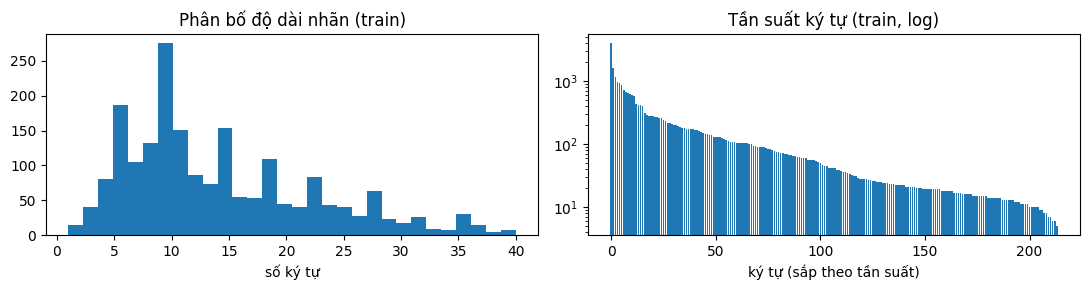

In [ ]:
SPLITS = ["train", "val", "test"]
dfs = {s: pd.read_csv(DATA_ROOT / s / "labels.csv", keep_default_na=False, dtype=str) for s in SPLITS}

print("=== 1. SỐ LƯỢNG MẪU ===")
for s in SPLITS:
    print(f"  {s:5s}: {len(dfs[s])}")

print("\n=== 2. KIỂM TRA LỖI ===")
problems = 0
for s, df in dfs.items():
    empty = (df["text"].str.strip() == "").sum()
    nonnfc = sum(not unicodedata.is_normalized("NFC", t) for t in df["text"])
    outside = sorted({c for t in df["text"] for c in t if c not in CHARSET})
    missing, corrupt = 0, 0
    for p in tqdm(df["image_path"], desc=f"Kiểm tra ảnh {s}", leave=False):
        fp = DATA_ROOT / p
        if not fp.exists():
            missing += 1; continue
        try:
            with Image.open(fp) as im:
                im.verify()
        except Exception:
            corrupt += 1
    problems += empty + nonnfc + len(outside) + missing + corrupt
    print(f"  {s:5s}: nhãn rỗng={empty} | không NFC={nonnfc} | ký tự lạ={outside} | mất file={missing} | ảnh hỏng={corrupt}")
assert problems == 0, "Dataset có lỗi, xem log phía trên."

print("\n=== 3. RÒ RỈ DỮ LIỆU GIỮA CÁC TẬP ===")
k = {s: {dedup_key(t) for t in dfs[s]["text"]} for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"  {a} ∩ {b}: {len(k[a] & k[b])} văn bản trùng (phải bằng 0)")
    assert len(k[a] & k[b]) == 0
for s in SPLITS:
    print(f"  {s}: {len(dfs[s])} mẫu, {dfs[s]['text'].nunique()} văn bản duy nhất")

print("\n=== 4. ĐỘ DÀI NHÃN (ký tự) ===")
for s in SPLITS:
    L = dfs[s]["text"].str.len()
    print(f"  {s:5s}: min={L.min()} | mean={L.mean():.1f} | max={L.max()}")

print("\n=== 5. ĐỘ PHỦ KÝ TỰ ===")
from collections import Counter
cnt = {s: Counter("".join(dfs[s]["text"])) for s in SPLITS}
missing_train = [c for c in CHARSET if cnt["train"][c] == 0]
print(f"  Ký tự trong vocab: {len(CHARSET)} | có trong train: {len(CHARSET) - len(missing_train)}")
print("  Ký tự chưa xuất hiện trong train:", missing_train if missing_train else "không có")
assert not missing_train, "Có ký tự chưa có mẫu trong train: tăng kích thước dataset hoặc tỷ lệ nhóm 'chuỗi ngẫu nhiên'."
rare = sorted([(c, cnt['train'][c]) for c in CHARSET if 0 < cnt['train'][c] < 30], key=lambda x: x[1])
print("  Ký tự hiếm (<30 lần trong train):", rare[:15] if rare else "không có")

low_ascii = {c: cnt["train"][c] for c in "abcdefghijklmnopqrstuvwxyz"}
up_ascii  = {c: cnt["train"][c] for c in "ABCDEFGHIJKLMNOPQRSTUVWXYZ"}
print("  Số lần xuất hiện chữ thường a-z (train): min =", min(low_ascii.values()), "| ít nhất:", sorted(low_ascii.items(), key=lambda x: x[1])[:4])
print("  Số lần xuất hiện CHỮ HOA A-Z (train)   : min =", min(up_ascii.values()),  "| ít nhất:", sorted(up_ascii.items(),  key=lambda x: x[1])[:4])

print("\n=== 6. KÍCH THƯỚC ẢNH (mẫu 500 ảnh train) ===")
samp = dfs["train"].sample(min(500, len(dfs["train"])), random_state=SEED)
sizes = [Image.open(DATA_ROOT / p).size for p in samp["image_path"]]
Ws, Hs = zip(*sizes)
print(f"  Rộng : min={min(Ws)} | mean={np.mean(Ws):.0f} | max={max(Ws)}")
print(f"  Cao  : min={min(Hs)} | mean={np.mean(Hs):.0f} | max={max(Hs)}")
print(f"  Tỷ lệ W/H trung bình: {np.mean(np.array(Ws)/np.array(Hs)):.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(dfs["train"]["text"].str.len(), bins=30); ax[0].set_title("Phân bố độ dài nhãn (train)"); ax[0].set_xlabel("số ký tự")
chars_sorted = sorted(CHARSET, key=lambda c: -cnt["train"][c])
ax[1].bar(range(len(chars_sorted)), [cnt["train"][c] for c in chars_sorted]); ax[1].set_yscale("log")
ax[1].set_title("Tần suất ký tự (train, log)"); ax[1].set_xlabel("ký tự (sắp theo tần suất)")
plt.tight_layout(); plt.show()

### Cell 1.10: Hiển thị ngẫu nhiên ảnh cùng nhãn
Mắt người kiểm tra: dấu tiếng Việt phải hiển thị đúng và khớp với nhãn.

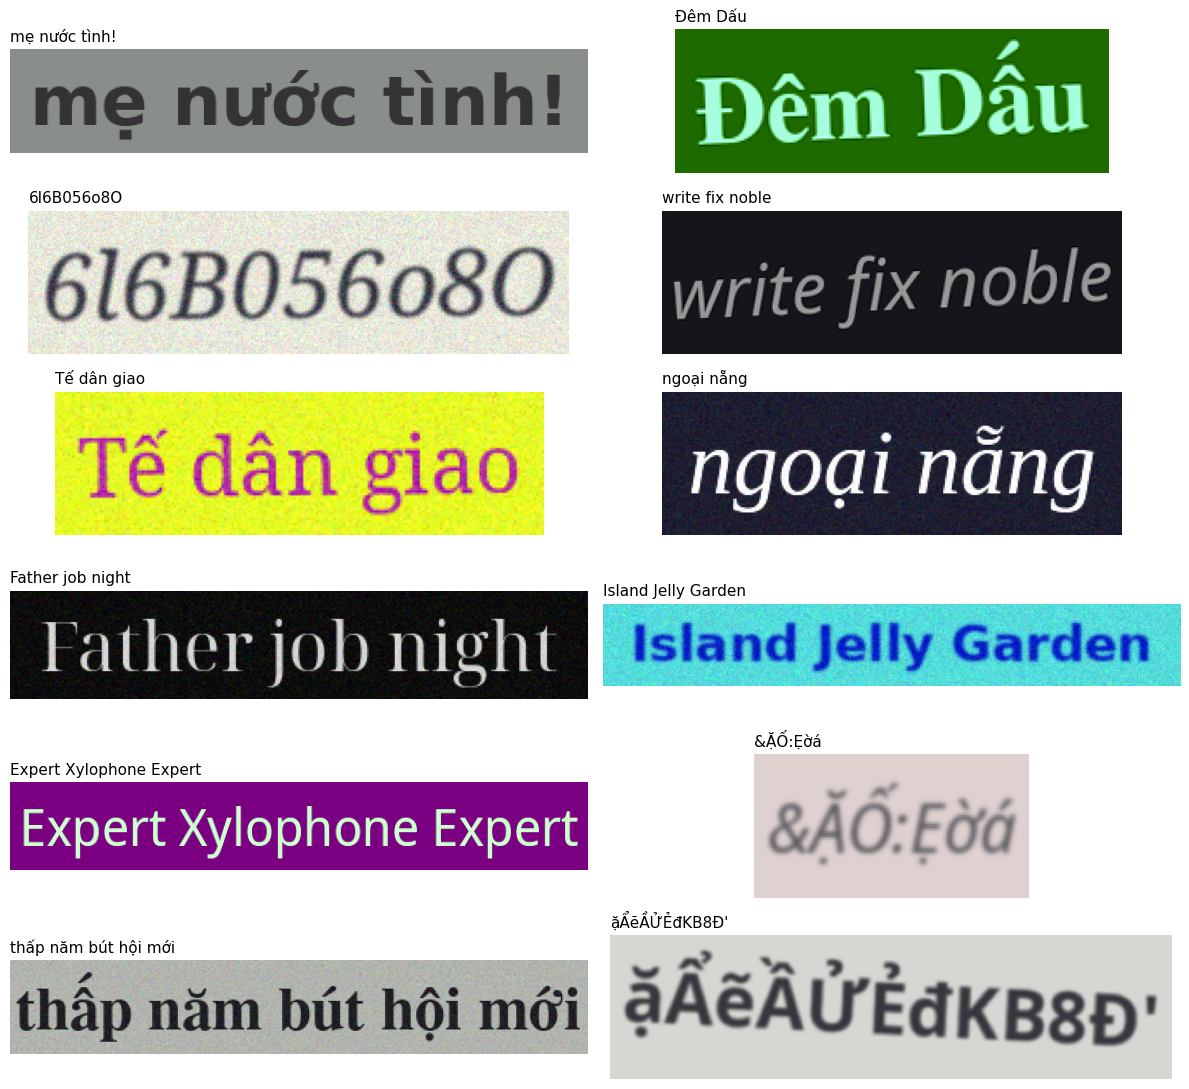


Trạng thái cuối giai đoạn 1:
  DATA_ROOT   = /content/dataset_small_en
  PROJECT_ROOT = /content/drive/MyDrive/OCR_CRNN
  Đã sẵn sàng cho Giai đoạn 2 (tiền xử lý).


In [ ]:
plt.rcParams["font.family"] = "DejaVu Sans"        # có glyph tiếng Việt cho tiêu đề
rows = dfs["train"].sample(12, random_state=1).reset_index(drop=True)
fig, axes = plt.subplots(6, 2, figsize=(12, 11))
for ax, (_, row) in zip(axes.ravel(), rows.iterrows()):
    ax.imshow(Image.open(DATA_ROOT / row["image_path"]))
    ax.set_title(row["text"], fontsize=11, loc="left"); ax.axis("off")
plt.tight_layout(); plt.show()

print("\nTrạng thái cuối giai đoạn 1:")
print("  DATA_ROOT   =", DATA_ROOT)
print("  PROJECT_ROOT =", PROJECT_ROOT)
print("  Đã sẵn sàng cho Giai đoạn 2 (tiền xử lý).")

### Cell 2.0: Cấu hình huấn luyện
`MODE`, `DATA_TAG`, đường dẫn Drive, `CHARSET` và dataset đã được thiết lập ở Giai đoạn 1 nên không khai báo lại. Muốn huấn luyện lại với số epoch khác: đổi `RUN_NAME` (checkpoint cũ được giữ nguyên).

In [ ]:
import sys, os, json, random, time, math, zipfile, unicodedata
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFilter, ImageEnhance, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# MODE, DATA_TAG, PROJECT_ROOT, DATA_ROOT, CHARSET đã có từ Giai đoạn 1 (Cell 1.3, 1.4, 1.8)
assert dataset_ready(), "Chưa có dataset: hãy chạy xong Giai đoạn 1 (Cell 1.8) trước."

# ---------------- CẤU HÌNH HUẤN LUYỆN ----------------
RUN_NAME = f"crnn_{DATA_TAG}"
EPOCHS = {"small": 40, "full": 30}[MODE]   # small: ~1.250 bước tối ưu, đủ để CTC thoát giai đoạn "toàn BLANK"
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-2
GRAD_CLIP = 5.0
PATIENCE = 8                         # early stopping theo val CER
WORKERS = 2
DEBUG_SUBSET = None                  # None = dùng toàn bộ; số nguyên = chỉ dùng N mẫu đầu mỗi tập (để chạy thử nhanh)
IMG_H = 48                           # chiều cao ảnh cố định
MAX_W = 800                          # giới hạn chiều rộng (hiếm khi chạm tới)
MIN_W = 32                           # chiều rộng tối thiểu của batch

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "| AMP:", USE_AMP, "| PyTorch:", torch.__version__)

CKPT_DIR = PROJECT_ROOT / "checkpoints" / RUN_NAME
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("Số ký tự trong charset:", len(CHARSET))
for s in ["train", "val", "test"]:
    print(f"  {s}: {len(pd.read_csv(DATA_ROOT / s / 'labels.csv'))} mẫu")

Device: cuda | AMP: True | PyTorch: 2.14.1+cu130
Số ký tự trong charset: 214
  train: 2000 mẫu
  val: 400 mẫu
  test: 400 mẫu


---
# GIAI ĐOẠN 2: TIỀN XỬ LÝ DỮ LIỆU

### Giải thích
- **Vì sao giữ tỷ lệ ảnh?** Hình dạng chữ (chiều rộng/cao của nét) là đặc trưng để phân biệt ký tự. Nếu ép mọi ảnh về cùng chiều rộng, ảnh ngắn bị kéo giãn, ảnh dài bị nén, làm biến dạng nét và dấu (ví dụ `ă` và `â`).
- **Vì sao chiều cao cố định?** CNN + lớp Linear cuối cần số kênh/chiều cao thống nhất để thu chiều cao về 1. Chiều rộng thì được phép thay đổi, vì chiều rộng chính là trục thời gian `T` cho BiLSTM.
- **Padding có tác dụng gì?** Các ảnh trong một batch phải cùng kích thước tensor. Ta đệm bên phải bằng **màu nền của chính ảnh đó** (không đệm số 0 cứng), để vùng đệm trông giống nền thật, không tạo "cạnh" giả. Độ dài hợp lệ từng ảnh được lưu lại để CTC bỏ qua phần đệm.
- **Augmentation giúp tổng quát hóa thế nào?** Mô hình thấy cùng một nội dung dưới nhiều biến thể (nghiêng nhẹ, lệch lề, sáng/tối, mờ, nhiễu) nên không học thuộc chi tiết cụ thể của từng ảnh. Chỉ áp dụng cho **tập train**; val/test giữ nguyên để đo công bằng. Không dùng phép co giãn tỷ lệ, để giữ đúng nguyên tắc không làm méo chữ.

### Cell 2.1: Hàm tiền xử lý, augmentation và Dataset

In [ ]:
def target_width(w, h):
    # chiều rộng sau khi resize về IMG_H, GIỮ nguyên tỷ lệ
    return int(min(max(1, round(w * IMG_H / h)), MAX_W))

def preprocess_pil(img_gray):
    # PIL ảnh xám -> (tensor 1xHxW trong [-1,1], giá trị nền dùng để padding)
    w, h = img_gray.size
    img = img_gray.resize((target_width(w, h), IMG_H), Image.LANCZOS)
    arr = (np.asarray(img, dtype=np.float32) / 255.0 - 0.5) / 0.5
    pad_value = float(np.median(np.concatenate([arr[:, 0], arr[:, -1]])))   # màu nền ước lượng ở mép ảnh
    return torch.from_numpy(arr).unsqueeze(0), pad_value

def augment_pil(img):
    # augmentation nhẹ, chỉ dùng cho tập train. Ảnh đầu vào là ảnh xám (mode L).
    edge = np.concatenate([np.asarray(img)[:, 0], np.asarray(img)[:, -1]])
    bg = int(np.median(edge))
    if random.random() < 0.4:                                   # nghiêng nhẹ
        img = img.rotate(random.uniform(-2.5, 2.5), resample=Image.BICUBIC, expand=True, fillcolor=bg)
    if random.random() < 0.3:                                   # xiên nhẹ (shear)
        s = random.uniform(-0.12, 0.12); w, h = img.size
        c = -s * h if s > 0 else 0
        img = img.transform((w + int(abs(s) * h) + 1, h), Image.AFFINE, (1, s, c, 0, 1, 0), resample=Image.BICUBIC, fillcolor=bg)
    if random.random() < 0.3:                                   # sáng / tương phản
        img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))
        img = ImageEnhance.Contrast(img).enhance(random.uniform(0.7, 1.3))
    if random.random() < 0.15:                                  # mờ
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.0)))
    if random.random() < 0.2:                                   # nhiễu
        a = np.asarray(img).astype(np.float32) + np.random.normal(0, random.uniform(3, 12), (img.size[1], img.size[0]))
        img = Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    if random.random() < 0.3:                                   # thay đổi lề
        l, r = random.randint(0, 8), random.randint(0, 8)
        t, b = random.randint(0, 4), random.randint(0, 4)
        img = ImageOps.expand(img, border=(l, t, r, b), fill=bg)
    return img

def pad_images(imgs, pads, min_w=MIN_W):
    # ghép list tensor (1,H,w_i) thành batch (B,1,H,maxW); đệm bên phải bằng màu nền của từng ảnh
    maxw = max(max(i.shape[-1] for i in imgs), min_w)
    x = torch.empty(len(imgs), 1, IMG_H, maxw)
    for k, (im, pv) in enumerate(zip(imgs, pads)):
        x[k] = pv
        x[k, :, :, :im.shape[-1]] = im
    widths = torch.tensor([i.shape[-1] for i in imgs], dtype=torch.long)
    return x, widths

class OCRDataset(Dataset):
    def __init__(self, split, augment=False, subset=None):
        self.split, self.augment = split, augment
        self.df = pd.read_csv(DATA_ROOT / split / "labels.csv", keep_default_na=False, dtype=str)
        if subset:
            self.df = self.df.iloc[:subset].reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        with Image.open(DATA_ROOT / row["image_path"]) as im:
            img = im.convert("L")
        if self.augment:
            img = augment_pil(img)
        x, pad = preprocess_pil(img)
        return x, row["text"], pad, row["image_path"]

train_ds = OCRDataset("train", augment=True,  subset=DEBUG_SUBSET)
val_ds   = OCRDataset("val",   augment=False, subset=DEBUG_SUBSET)
test_ds  = OCRDataset("test",  augment=False, subset=DEBUG_SUBSET)
print(len(train_ds), len(val_ds), len(test_ds))

2000 400 400


### Cell 2.2: Trực quan hóa tiền xử lý, augmentation và padding
Hàng 1: ảnh gốc. Hàng 2: sau tiền xử lý (xám, chiều cao 48, giữ tỷ lệ). Hàng 3: sau augmentation. Cuối cell in kích thước batch sau padding.

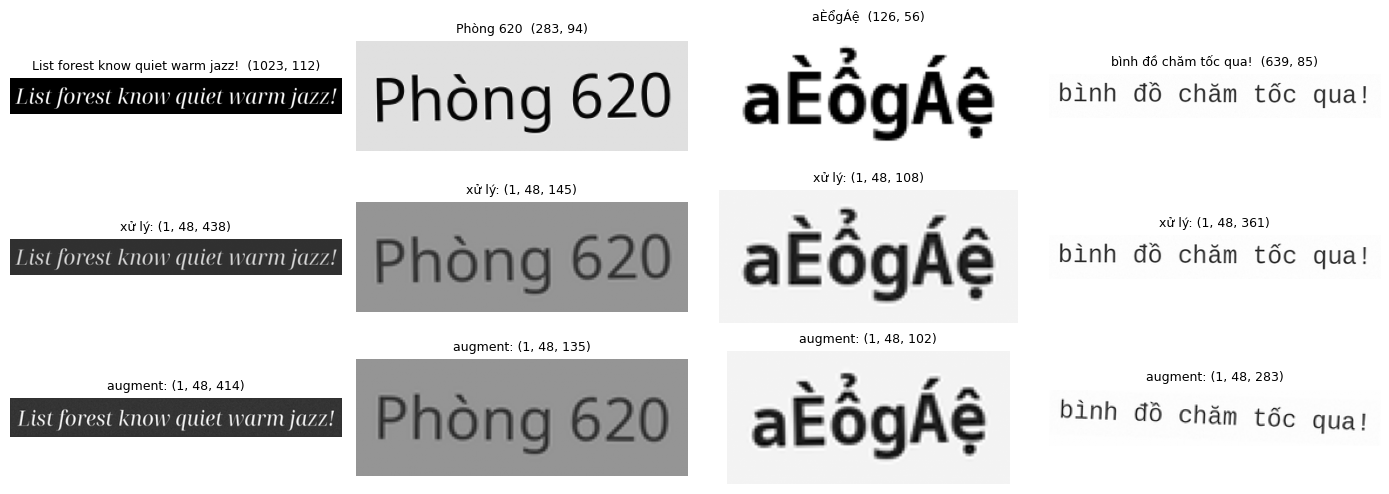

Batch sau padding: (8, 1, 48, 438) | chiều rộng thật từng ảnh: [438, 145, 103, 283, 238, 271, 379, 387]
Giá trị pixel: min=-1.00 max=1.00 (khoảng [-1, 1])


In [ ]:
plt.rcParams["font.family"] = "DejaVu Sans"
idxs = [0, 1, 2, 3]
fig, axes = plt.subplots(3, len(idxs), figsize=(14, 5))
for c, i in enumerate(idxs):
    row = train_ds.df.iloc[i]
    raw = Image.open(DATA_ROOT / row["image_path"]).convert("L")
    x, _ = preprocess_pil(raw)
    aug, _ = preprocess_pil(augment_pil(raw))
    axes[0, c].imshow(raw, cmap="gray");                         axes[0, c].set_title(f'{row["text"]}  {raw.size}', fontsize=9)
    axes[1, c].imshow(x[0], cmap="gray", vmin=-1, vmax=1);       axes[1, c].set_title(f"xử lý: {tuple(x.shape)}", fontsize=9)
    axes[2, c].imshow(aug[0], cmap="gray", vmin=-1, vmax=1);     axes[2, c].set_title(f"augment: {tuple(aug.shape)}", fontsize=9)
    for r in range(3): axes[r, c].axis("off")
plt.tight_layout(); plt.show()

samples = [train_ds[i] for i in range(8)]
xb, wb = pad_images([s[0] for s in samples], [s[2] for s in samples])
print("Batch sau padding:", tuple(xb.shape), "| chiều rộng thật từng ảnh:", wb.tolist())
print("Giá trị pixel: min=%.2f max=%.2f (khoảng [-1, 1])" % (xb.min(), xb.max()))

---
# GIAI ĐOẠN 3: XÂY DỰNG KIẾN TRÚC CRNN

### Vocabulary
Chỉ số **0 dành riêng cho BLANK** của CTC; ký tự thật được đánh số từ 1. Do đó `NUM_CLASSES = len(CHARSET) + 1`.

### Sơ đồ kích thước tensor (ảnh đầu vào `B×1×48×W`)
| Tầng | Đầu ra | Ghi chú |
|---|---|---|
| Conv(1→64) + BN + ReLU, MaxPool(2,2) | `B×64×24×W/2` | giảm cả cao lẫn rộng |
| Conv(64→128) + BN + ReLU, MaxPool(2,1) | `B×128×12×W/2` | chỉ giảm chiều cao |
| Conv(128→256) ×2 + BN + ReLU, MaxPool(2,1) | `B×256×6×W/2` | |
| Conv(256→512) ×2 + BN + ReLU, MaxPool(2,1) | `B×512×3×W/2` | |
| Conv(512→512, kernel 3×1) + BN + ReLU | `B×512×1×W/2` | thu chiều cao về 1 |
| squeeze + permute | `T×B×512` với `T = W/2` | chuỗi đặc trưng cho LSTM |
| BiLSTM 2 tầng (hidden 256 × 2 chiều) | `T×B×512` | |
| Linear(512 → NUM_CLASSES) | `T×B×NUM_CLASSES` | logits theo từng bước thời gian |

**Vì sao chỉ giảm chiều rộng 2 lần (T = W/2)?** CTC cần số bước thời gian `T` đủ lớn: tối thiểu bằng độ dài nhãn cộng số lần ký tự lặp liên tiếp (cần BLANK ở giữa). Các ký tự hẹp như `l`, `i`, `1` chiếm rất ít pixel; giảm 4 lần chiều rộng dễ làm `T` không đủ.

### Chuyển đổi đặc trưng `(B, C, H, W) → (T, B, Features)`
Sau CNN, `H = 1` nên `squeeze(2)` cho `(B, C, W')`. Mỗi **cột** của feature map là một bước thời gian (quét từ trái sang phải), `Features = C = 512`. `permute(2, 0, 1)` đưa về `(T, B, F)`, đúng định dạng mặc định của `nn.LSTM` (batch_first=False) và của `nn.CTCLoss`.

### Vai trò BiLSTM
CNN chỉ nhìn một vùng cục bộ. LSTM học ngữ cảnh theo chuỗi (ví dụ dấu nằm ở cột kế bên chữ, hoặc hai nét ghép thành một ký tự). **Bi**LSTM đọc cả trái→phải và phải→trái nên mỗi bước thời gian có thông tin của cả hai phía, quan trọng với tiếng Việt vì dấu thanh và dấu mũ phụ thuộc nguyên âm ở gần.

### Cell 3.1: Vocabulary và collate function (tạo batch)

In [ ]:
BLANK = 0
char2idx = {c: i + 1 for i, c in enumerate(CHARSET)}          # ký tự thật: 1..N
idx2char = {i: c for c, i in char2idx.items()}
NUM_CLASSES = len(CHARSET) + 1                                  # +1 cho BLANK
assert NUM_CLASSES == len(char2idx) + 1 and BLANK not in idx2char
print("NUM_CLASSES =", NUM_CLASSES, "(gồm BLANK = 0)")

def encode(text):
    return [char2idx[c] for c in text]

def collate_fn(batch):
    imgs, texts, pads, paths = zip(*batch)
    x, widths = pad_images(imgs, pads)
    enc = [encode(t) for t in texts]
    return {
        "images": x,
        "widths": widths,
        "targets": torch.tensor([i for e in enc for i in e], dtype=torch.long),   # nối phẳng, đúng định dạng CTCLoss
        "target_lengths": torch.tensor([len(e) for e in enc], dtype=torch.long),
        "texts": list(texts),
        "paths": list(paths),
    }

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=WORKERS,
                      collate_fn=collate_fn, pin_memory=(DEVICE.type == "cuda"),
                      persistent_workers=(WORKERS > 0))

train_loader, val_loader, test_loader = make_loader(train_ds, True), make_loader(val_ds, False), make_loader(test_ds, False)
b = next(iter(train_loader))
print({k: (tuple(v.shape) if torch.is_tensor(v) else len(v)) for k, v in b.items()})

NUM_CLASSES = 215 (gồm BLANK = 0)
{'images': (64, 1, 48, 601), 'widths': (64,), 'targets': (775,), 'target_lengths': (64,), 'texts': 64, 'paths': 64}


### Cell 3.2: Mô hình CRNN (CNN + BiLSTM + Linear)

In [ ]:
class CRNN(nn.Module):
    def __init__(self, num_classes, in_ch=1, rnn_hidden=256, rnn_layers=2, dropout=0.3):
        super().__init__()
        def block(i, o):
            return [nn.Conv2d(i, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
        self.cnn = nn.Sequential(
            *block(in_ch, 64),  nn.MaxPool2d((2, 2), (2, 2)),          # H: 48 -> 24, W: /2
            *block(64, 128),    nn.MaxPool2d((2, 1), (2, 1)),          # H: 24 -> 12
            *block(128, 256), *block(256, 256), nn.MaxPool2d((2, 1), (2, 1)),   # H: 12 -> 6
            *block(256, 512), *block(512, 512), nn.MaxPool2d((2, 1), (2, 1)),   # H: 6 -> 3
            nn.Conv2d(512, 512, kernel_size=(3, 1), bias=False), nn.BatchNorm2d(512), nn.ReLU(inplace=True),  # H: 3 -> 1
        )
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(512, rnn_hidden, num_layers=rnn_layers, bidirectional=True,
                           dropout=dropout if rnn_layers > 1 else 0.0)
        self.fc = nn.Linear(2 * rnn_hidden, num_classes)
        self.cfg = dict(num_classes=num_classes, in_ch=in_ch, rnn_hidden=rnn_hidden, rnn_layers=rnn_layers, dropout=dropout)

    @staticmethod
    def input_lengths(widths):
        return widths // 2                                  # T = W/2 (chỉ MaxPool đầu tiên giảm chiều rộng)

    def forward(self, x):                                   # x: (B, 1, 48, W)
        f = self.cnn(x)                                     # (B, 512, 1, W/2)
        assert f.shape[2] == 1, f"Chiều cao feature map phải bằng 1, nhận {f.shape[2]}"
        f = f.squeeze(2).permute(2, 0, 1)                   # (T, B, 512)
        f, _ = self.rnn(self.drop(f))                       # (T, B, 512)
        return self.fc(self.drop(f))                        # (T, B, NUM_CLASSES)

model = CRNN(NUM_CLASSES).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Số tham số: {n_params/1e6:.2f} M")

Số tham số: 8.55 M


### Cell 3.3: Kiểm tra kích thước tensor sau từng tầng
Đối chiếu với bảng ở đầu giai đoạn.

In [ ]:
model.eval()
with torch.no_grad():
    t = torch.zeros(2, 1, IMG_H, 160, device=DEVICE)
    print("input:", tuple(t.shape))
    for layer in model.cnn:
        t = layer(t)
        if isinstance(layer, (nn.MaxPool2d,)) or (isinstance(layer, nn.ReLU) and t.shape[2] == 1):
            print(f"  sau {layer.__class__.__name__:10s}:", tuple(t.shape))
    out = model(torch.zeros(2, 1, IMG_H, 160, device=DEVICE))
    print("logits (T, B, C):", tuple(out.shape), "| mong đợi T =", 160 // 2, ", C =", NUM_CLASSES)
    assert out.shape == (80, 2, NUM_CLASSES)

input: (2, 1, 48, 160)
  sau MaxPool2d : (2, 64, 24, 80)
  sau MaxPool2d : (2, 128, 12, 80)
  sau MaxPool2d : (2, 256, 6, 80)
  sau MaxPool2d : (2, 512, 3, 80)
  sau ReLU      : (2, 512, 1, 80)
logits (T, B, C): (80, 2, 215) | mong đợi T = 80 , C = 215


---
# GIAI ĐOẠN 4: CTC LOSS VÀ DECODER

### CTC là gì?
Mô hình xuất ra một phân phối ký tự cho **mỗi bước thời gian** (`T` bước), nhưng chuỗi nhãn chỉ có `L` ký tự (thường `L < T`) và ta **không biết** ký tự nào nằm ở bước nào. CTC giải quyết bằng cách **cộng xác suất của mọi cách căn chỉnh hợp lệ** giữa chuỗi `T` bước và nhãn, rồi tối thiểu hóa `-log P(nhãn | ảnh)`.

- **Không cần căn chỉnh từng ký tự**: tổng trên mọi đường đi hợp lệ được tính bằng quy hoạch động (thuật toán forward-backward), nên không cần ai gán nhãn vị trí.
- **BLANK**: ký hiệu "không phát ký tự" (không phải khoảng trắng). Nó làm hai việc: (1) lấp các bước không có chữ; (2) **ngăn việc gộp nhầm**, ví dụ nhãn `ll` phải được biểu diễn là `l, BLANK, l` vì `l, l` sẽ bị gộp thành một `l`.
- **Quy tắc rút gọn đường đi → nhãn**: *gộp các ký tự lặp liên tiếp trước, rồi mới bỏ BLANK*.
- **Độ dài khác nhau**: `input_lengths` (số bước hợp lệ mỗi ảnh) và `target_lengths` (độ dài mỗi nhãn) được truyền riêng cho từng mẫu.
- **Đầu ra theo thời gian khác chuỗi cuối cùng**: đầu ra có `T` bước (nhiều BLANK, ký tự lặp); chuỗi cuối cùng có `L` ký tự sau khi decoder rút gọn.

### Điều kiện bắt buộc của `nn.CTCLoss`
1. Đầu vào là **log-probabilities** (`log_softmax`) có dạng `(T, B, C)`.
2. `blank` phải đúng chỉ số BLANK của vocabulary (ở đây 0).
3. `input_lengths[i] ≥ target_lengths[i] + (số cặp ký tự lặp liên tiếp)` thì mới có đường đi hợp lệ; nếu không loss là `inf`. Ta kiểm tra điều kiện này trên toàn dataset và dùng `zero_infinity=True` như lưới an toàn.
4. `input_lengths ≤ T` và `target_lengths ≤ độ dài nhãn thực`.

### Cell 4.1: Hàm loss và kiểm tra điều kiện CTC trên toàn bộ dataset

In [ ]:
ctc_loss_fn = nn.CTCLoss(blank=BLANK, reduction="mean", zero_infinity=True)

def compute_loss(logits, targets, input_lengths, target_lengths):
    log_probs = F.log_softmax(logits.float(), dim=2)           # (T, B, C), tính ở float32 cho ổn định
    return ctc_loss_fn(log_probs, targets, input_lengths.cpu(), target_lengths.cpu())

def required_frames(text):
    # số bước thời gian tối thiểu để CTC biểu diễn được `text`: độ dài + số cặp lặp liên tiếp
    return len(text) + sum(1 for i in range(1, len(text)) if text[i] == text[i - 1])

def check_ctc_feasibility(split):
    df = pd.read_csv(DATA_ROOT / split / "labels.csv", keep_default_na=False, dtype=str)
    if DEBUG_SUBSET: df = df.iloc[:DEBUG_SUBSET]
    bad, margins = [], []
    for p, t in zip(df["image_path"], df["text"]):
        with Image.open(DATA_ROOT / p) as im:
            w, h = im.size
        T = target_width(w, h) // 2
        m = T - required_frames(t)
        margins.append(m)
        if m < 0: bad.append((p, t, T, required_frames(t)))
    return len(df), bad, min(margins)

for s in ["train", "val", "test"]:
    n, bad, mn = check_ctc_feasibility(s)
    print(f"{s:5s}: {n} mẫu | vi phạm điều kiện T >= L + lặp: {len(bad)} | biên an toàn nhỏ nhất: {mn} bước")
    for b_ in bad[:3]: print("     ví dụ:", b_)

train: 2000 mẫu | vi phạm điều kiện T >= L + lặp: 0 | biên an toàn nhỏ nhất: 14 bước
val  : 400 mẫu | vi phạm điều kiện T >= L + lặp: 0 | biên an toàn nhỏ nhất: 19 bước
test : 400 mẫu | vi phạm điều kiện T >= L + lặp: 0 | biên an toàn nhỏ nhất: 24 bước


### Cell 4.2: Greedy Decoder và Beam Search Decoder (tự cài đặt)
**Greedy:** `argmax` mỗi bước → gộp ký tự lặp liên tiếp → bỏ BLANK.
**Beam Search (prefix beam search):** giữ `beam_width` chuỗi tiền tố có xác suất cao nhất, cộng xác suất của mọi đường đi dẫn tới cùng một chuỗi (tách riêng xác suất kết thúc bằng BLANK / bằng ký tự). Có cắt tỉa các ký tự xác suất < 0,001 ở mỗi bước để chạy nhanh. Không dùng mô hình ngôn ngữ ngoài.

In [ ]:
def greedy_from_logprobs(lp):
    # lp: numpy (T, C). Gộp lặp TRƯỚC, bỏ BLANK SAU.
    best = lp.argmax(axis=1)
    out, prev = [], -1
    for s in best:
        if s != prev and s != BLANK:
            out.append(idx2char[int(s)])
        prev = s
    return "".join(out)

NEG_INF = -float("inf")
def _lse(a, b):
    if a == NEG_INF: return b
    if b == NEG_INF: return a
    m = max(a, b)
    return m + math.log1p(math.exp(-abs(a - b)))

def beam_search_logprobs(lp, beam_width=10, prune_logp=math.log(1e-3)):
    # prefix beam search. lp: numpy (T, C) log-prob. Trả về (chuỗi, log-xác-suất).
    beams = {(): (0.0, NEG_INF)}                 # prefix -> (log P kết thúc BLANK, log P kết thúc ký tự)
    for t in range(lp.shape[0]):
        row = lp[t]
        cand = np.nonzero(row > prune_logp)[0]
        if cand.size == 0:
            cand = np.array([int(row.argmax())])
        nb = defaultdict(lambda: [NEG_INF, NEG_INF])
        for prefix, (pb, pnb) in beams.items():
            ptot = _lse(pb, pnb)
            for c in cand:
                p = float(row[c])
                if c == BLANK:
                    e = nb[prefix]; e[0] = _lse(e[0], ptot + p)
                else:
                    last = prefix[-1] if prefix else None
                    newp = prefix + (int(c),)
                    if c == last:                       # ký tự lặp: chỉ tách thành ký tự mới nếu trước đó có BLANK
                        e = nb[newp];   e[1] = _lse(e[1], pb + p)
                        e2 = nb[prefix]; e2[1] = _lse(e2[1], pnb + p)     # không có BLANK -> gộp vào ký tự cũ
                    else:
                        e = nb[newp];   e[1] = _lse(e[1], ptot + p)
        top = sorted(nb.items(), key=lambda kv: -_lse(kv[1][0], kv[1][1]))[:beam_width]
        beams = {k: (v[0], v[1]) for k, v in top}
    best_prefix, (pb, pnb) = max(beams.items(), key=lambda kv: _lse(*kv[1]))
    return "".join(idx2char[i] for i in best_prefix), _lse(pb, pnb)

### Cell 4.3: Unit test cho decoder và CTC Loss
Kiểm tra bằng ví dụ có đáp án biết trước. Test cuối đối chiếu xác suất của beam search với `nn.CTCLoss` (hai cách tính độc lập phải cho cùng kết quả).

In [ ]:
a, b_, l_ = char2idx["a"], char2idx["b"], char2idx["l"]
def onehot_seq(seq, C=NUM_CLASSES):
    lp = np.full((len(seq), C), -20.0, dtype=np.float32)
    for t, s in enumerate(seq): lp[t, s] = 0.0
    return lp

# 1) gộp lặp trước, bỏ BLANK sau
assert greedy_from_logprobs(onehot_seq([a, a, BLANK, a, b_, b_])) == "aab"
assert greedy_from_logprobs(onehot_seq([BLANK, l_, l_, BLANK, l_, BLANK])) == "ll"     # BLANK giữa hai 'l' giữ lại cả hai
assert greedy_from_logprobs(onehot_seq([l_, l_, l_])) == "l"                           # không BLANK -> gộp thành một
assert greedy_from_logprobs(onehot_seq([BLANK, BLANK])) == ""
# 2) beam search khớp greedy khi phân phối rất nhọn
assert beam_search_logprobs(onehot_seq([a, a, BLANK, a, b_, b_]))[0] == "aab"
assert beam_search_logprobs(onehot_seq([BLANK, l_, l_, BLANK, l_, BLANK]))[0] == "ll"
# 3) đối chiếu với nn.CTCLoss trên ví dụ nhỏ: T=2, lớp {BLANK, 'a'}
C2 = 2
p = np.array([[0.4, 0.6], [0.4, 0.6]], dtype=np.float32)       # P(blank)=0.4, P('a')=0.6 mỗi bước
lp2 = np.log(p)
saved_map = dict(idx2char); idx2char = {1: "a"}
text, score = beam_search_logprobs(lp2)
idx2char = saved_map
# P("a") = (a,-) + (-,a) + (a,a) = 0.24 + 0.24 + 0.36 = 0.84
ctc_val = nn.CTCLoss(blank=0, reduction="sum")(torch.from_numpy(lp2).unsqueeze(1), torch.tensor([[1]]),
                                                 torch.tensor([2]), torch.tensor([1])).item()
print(f"beam: '{text}' log P = {score:.6f} | -CTCLoss = {-ctc_val:.6f} | log(0.84) = {math.log(0.84):.6f}")
assert text == "a" and abs(score - (-ctc_val)) < 1e-4 and abs(score - math.log(0.84)) < 1e-4
print("Tất cả unit test decoder / CTC đều đạt.")

beam: 'a' log P = -0.174353 | -CTCLoss = -0.174353 | log(0.84) = -0.174353
Tất cả unit test decoder / CTC đều đạt.


---
# GIAI ĐOẠN 5: HUẤN LUYỆN

- **Optimizer:** AdamW (`lr=1e-3`, `weight_decay=1e-2`), **scheduler:** OneCycleLR (khởi động chậm rồi giảm dần: CTC thường kẹt ở trạng thái "toàn BLANK" nếu lr cao ngay từ đầu).
- **Mixed precision (AMP)** trên GPU để nhanh hơn và tiết kiệm VRAM; **loss CTC luôn tính ở float32**.
- **Gradient clipping** (5.0) để tránh nổ gradient của LSTM.
- **Bỏ qua batch có loss không hữu hạn** (NaN/Inf), có đếm số lần để theo dõi.
- **Checkpoint:** `last.pt` lưu mỗi epoch (mô hình, optimizer, scheduler, scaler, lịch sử) để **tiếp tục huấn luyện**; `best.pt` lưu mô hình có **val CER thấp nhất**.
- **Early stopping** khi val CER (hòa thì val loss) không cải thiện sau `PATIENCE` epoch. Chỉ bắt đầu đếm khi CER đã xuống dưới 100%: đầu quá trình CTC thường có giai đoạn "toàn BLANK" (CER = 100% liên tục) mà vẫn đang học.
- Chạy lại cell này sau khi đã huấn luyện xong sẽ **không huấn luyện lại**, chỉ nạp kết quả.
- Lưu ý: kế hoạch lr (OneCycle) gắn với `EPOCHS`. Muốn đổi số epoch, đổi `RUN_NAME` ở Cell 2.0.

### Cell 5.1: Hàm tính CER (tự cài đặt, có phân tách S/D/I) và chuẩn hóa văn bản
CER = (S + D + I) / N, tính trên **toàn tập** (tổng lỗi chia tổng số ký tự tham chiếu). Khoảng trắng được tính là ký tự.

In [ ]:
def norm_eval(t):
    # quy tắc chuẩn hóa NHẤT QUÁN cho cả ref và pred: NFC + bỏ khoảng trắng thừa. Phân biệt hoa/thường.
    return " ".join(unicodedata.normalize("NFC", t).split())

def align_ops(ref, hyp):
    n, m = len(ref), len(hyp)
    dp = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): dp[i][0] = i
    for j in range(m + 1): dp[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            dp[i][j] = min(dp[i-1][j] + 1, dp[i][j-1] + 1, dp[i-1][j-1] + (ref[i-1] != hyp[j-1]))
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and dp[i][j] == dp[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            ops.append(("eq" if ref[i-1] == hyp[j-1] else "sub", ref[i-1], hyp[j-1])); i -= 1; j -= 1
        elif i > 0 and dp[i][j] == dp[i-1][j] + 1:
            ops.append(("del", ref[i-1], "")); i -= 1
        else:
            ops.append(("ins", "", hyp[j-1])); j -= 1
    return ops[::-1]

def corpus_cer(refs, hyps):
    S = D = I = N = 0
    for r, h in zip(refs, hyps):
        r, h = norm_eval(r), norm_eval(h)
        ops = align_ops(r, h)
        S += sum(o[0] == "sub" for o in ops); D += sum(o[0] == "del" for o in ops); I += sum(o[0] == "ins" for o in ops)
        N += len(r)
    return dict(CER=(S + D + I) / max(N, 1), S=S, D=D, I=I, N=N)

def word_accuracy(refs, hyps):
    return float(np.mean([norm_eval(r) == norm_eval(h) for r, h in zip(refs, hyps)]))

# kiểm tra nhanh
assert corpus_cer(["abc"], ["abc"])["CER"] == 0
r_ = corpus_cer(["abcd"], ["abxd"]); assert (r_["S"], r_["D"], r_["I"]) == (1, 0, 0)
r_ = corpus_cer(["abcd"], ["abd"]);  assert (r_["S"], r_["D"], r_["I"]) == (0, 1, 0)
r_ = corpus_cer(["abd"], ["abcd"]);  assert (r_["S"], r_["D"], r_["I"]) == (0, 0, 1)
print("CER ok.")

CER ok.


### Cell 5.2: Vòng huấn luyện (có resume + early stopping)

In [ ]:
LAST, BEST, HIST = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt", CKPT_DIR / "history.json"

def atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp); os.replace(tmp, path)

@torch.no_grad()
def forward_logprobs(x):
    return F.log_softmax(model(x).float(), dim=2)

def run_epoch(loader, train, optimizer=None, scheduler=None, scaler=None):
    model.train(train)
    total, n, skipped = 0.0, 0, 0
    refs, hyps = [], []
    for batch in tqdm(loader, leave=False, desc="train" if train else "val"):
        x = batch["images"].to(DEVICE, non_blocking=True)
        in_len = model.input_lengths(batch["widths"])
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)                                        # (T, B, C)
            loss = compute_loss(logits, batch["targets"].to(DEVICE), in_len, batch["target_lengths"])
        if not torch.isfinite(loss):
            skipped += 1
            if train: optimizer.zero_grad(set_to_none=True)
            continue
        B = x.shape[0]
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            scheduler.step()
        else:
            lp = F.log_softmax(logits.float(), dim=2).cpu().numpy()      # (T, B, C)
            for b in range(B):
                hyps.append(greedy_from_logprobs(lp[:int(in_len[b]), b]))
            refs += batch["texts"]
        total += loss.item() * B; n += B
    out = dict(loss=total / max(n, 1), skipped=skipped)
    if not train and refs:
        out["cer"] = corpus_cer(refs, hyps)["CER"]
        out["word_acc"] = word_accuracy(refs, hyps)
    return out

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader), pct_start=0.15)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
state = dict(epoch=0, best_cer=float("inf"), bad_epochs=0, finished=False, history=[])

if LAST.exists():
    ck = torch.load(LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    state = ck["state"]
    print(f"Tìm thấy checkpoint: đã huấn luyện {state['epoch']}/{EPOCHS} epoch | best val CER = {state['best_cer']*100:.2f}%"
          + (" | ĐÃ HOÀN TẤT, bỏ qua huấn luyện" if state["finished"] else " | tiếp tục huấn luyện"))
else:
    print("Chưa có checkpoint, huấn luyện từ đầu.")

while state["epoch"] < EPOCHS and not state["finished"]:
    ep = state["epoch"] + 1
    t0 = time.time()
    tr = run_epoch(train_loader, True, optimizer, scheduler, scaler)
    va = run_epoch(val_loader, False)
    lr_now = optimizer.param_groups[0]["lr"]
    state["epoch"] = ep
    rec = dict(epoch=ep, train_loss=tr["loss"], val_loss=va["loss"], val_cer=va["cer"], val_word_acc=va["word_acc"],
               lr=lr_now, seconds=time.time() - t0, skipped=tr["skipped"] + va["skipped"])
    state["history"].append(rec)
    state.setdefault("best_loss", float("inf"))
    improved = (va["cer"], va["loss"]) < (state["best_cer"], state["best_loss"])   # CER trước, hòa thì xét val loss
    if improved:
        state["best_cer"], state["best_loss"], state["bad_epochs"] = va["cer"], va["loss"], 0
        atomic_save(dict(model=model.state_dict(), cfg=model.cfg, charset=CHARSET, epoch=ep, val_cer=va["cer"],
                         img_h=IMG_H), BEST)
    else:
        state["bad_epochs"] += 1
    if state["best_cer"] < 1.0 and state["bad_epochs"] >= PATIENCE:    # chỉ early-stop khi mô hình đã bắt đầu học (CER < 100%)
        state["finished"] = True; print(f"Early stopping tại epoch {ep}.")
    if ep == EPOCHS:
        state["finished"] = True
    atomic_save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                     scaler=scaler.state_dict(), state=state), LAST)
    json.dump(state["history"], open(HIST, "w"), indent=1)
    print(f"Epoch {ep:02d}/{EPOCHS} | train_loss {tr['loss']:.4f} | val_loss {va['loss']:.4f} | val_CER {va['cer']*100:6.2f}% "
          f"| val_WordAcc {va['word_acc']*100:6.2f}% | lr {lr_now:.2e} | {rec['seconds']:.0f}s"
          + (" | *best*" if improved else "") + (f" | bỏ qua {rec['skipped']} batch" if rec["skipped"] else ""))

print("Huấn luyện xong. Best val CER = %.2f%%" % (state["best_cer"] * 100))

Chưa có checkpoint, huấn luyện từ đầu.


train:   0%|          | 0/32 [00:00<?, ?it/s]

/tmp/ipykernel_606/4292902836.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


val:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 01/40 | train_loss 31.0970 | val_loss 23.8932 | val_CER 100.00% | val_WordAcc   0.00% | lr 1.05e-04 | 17s | *best*


train:   0%|          | 0/32 [00:00<?, ?it/s]

... (112 outputs left out)

Epoch 39/40 | train_loss 0.1975 | val_loss 0.2401 | val_CER   4.61% | val_WordAcc  63.50% | lr 2.01e-06 | 17s | *best*


train:   0%|          | 0/32 [00:00<?, ?it/s]

val:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 40/40 | train_loss 0.1947 | val_loss 0.2393 | val_CER   4.66% | val_WordAcc  63.00% | lr 6.08e-09 | 17s
Huấn luyện xong. Best val CER = 4.61%


### Cell 5.3: Đường cong Training Loss, Validation Loss và Validation CER

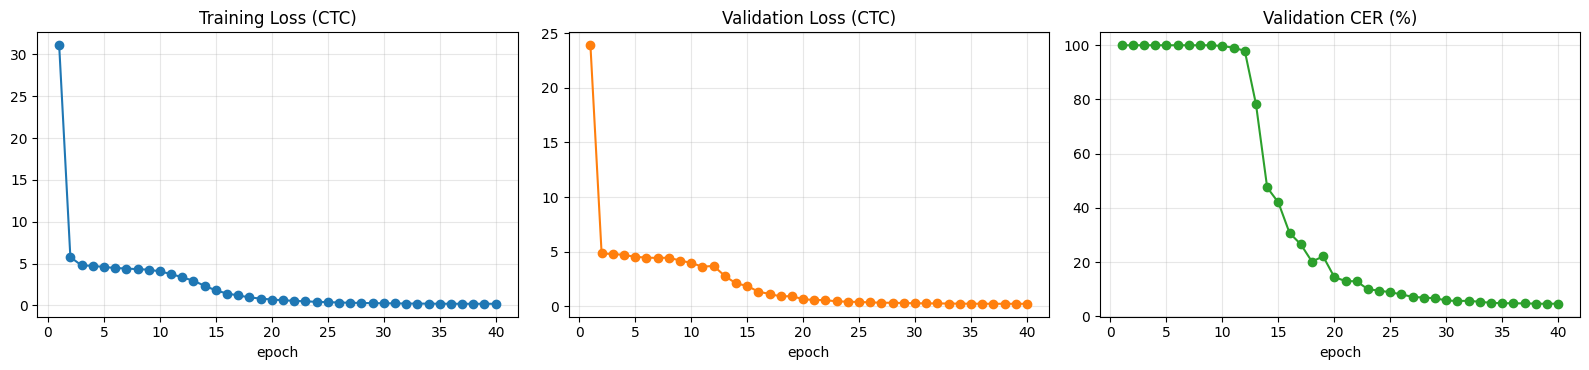

,epoch,train_loss,val_loss,val_cer,val_word_acc,lr,seconds
0,1,31.0970,23.8932,1.0000,0.0000,0.0001,17.3330
1,2,5.7744,4.8426,1.0000,0.0000,0.0003,14.9755
2,3,4.7812,4.7960,1.0000,0.0000,0.0005,15.6996
3,4,4.7371,4.7137,1.0000,0.0000,0.0008,15.8612
4,5,4.5909,4.5321,1.0000,0.0000,0.0009,15.4080
5,6,4.4778,4.4702,1.0000,0.0000,0.0010,15.9937
6,7,4.4067,4.4294,1.0000,0.0000,0.0010,15.6873
7,8,4.3381,4.4622,1.0000,0.0000,0.0010,16.3167
8,9,4.2708,4.1964,1.0000,0.0000,0.0010,16.3339
9,10,4.0715,3.9838,0.9972,0.0000,0.0010,16.7303


In [ ]:
hist = pd.DataFrame(state["history"])
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(hist.epoch, hist.train_loss, "o-"); ax[0].set_title("Training Loss (CTC)"); ax[0].set_xlabel("epoch")
ax[1].plot(hist.epoch, hist.val_loss, "o-", color="tab:orange"); ax[1].set_title("Validation Loss (CTC)"); ax[1].set_xlabel("epoch")
ax[2].plot(hist.epoch, hist.val_cer * 100, "o-", color="tab:green"); ax[2].set_title("Validation CER (%)"); ax[2].set_xlabel("epoch")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(CKPT_DIR / "loss_curves.png", dpi=130); plt.show()
hist[["epoch", "train_loss", "val_loss", "val_cer", "val_word_acc", "lr", "seconds"]].round(4)

---
# GIAI ĐOẠN 6: ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP

- **CER** = (S + D + I) / N: tỷ lệ lỗi ở mức ký tự, tính trên toàn tập test. CER = 5% nghĩa là trung bình cứ 100 ký tự tham chiếu thì cần ~5 phép sửa (thay/xóa/chèn) để thành văn bản đúng. CER **có thể vượt 100%** nếu chèn quá nhiều.
- **Word Accuracy** (theo định nghĩa đề bài) = tỷ lệ mẫu mà **toàn bộ chuỗi** dự đoán giống tham chiếu 100%. Đây là chỉ số khắt khe, **không phải** `1 - WER`.
- Cả hai so sánh sau `norm_eval` (NFC + bỏ khoảng trắng thừa, phân biệt hoa/thường).
- **Thời gian dự đoán** = (thời gian forward của mô hình + thời gian giải mã) chia số ảnh, đo khi chạy theo batch, **không** gồm thời gian đọc ảnh. Beam search chạy trên CPU bằng Python thuần nên chậm hơn greedy; đó là đặc điểm của cài đặt này.

### Cell 6.1: Nạp mô hình tốt nhất và suy luận trên tập test

In [ ]:
assert BEST.exists(), "Chưa có best.pt, hãy chạy Cell 5.2."
ck_best = torch.load(BEST, map_location=DEVICE, weights_only=False)
model = CRNN(**ck_best["cfg"]).to(DEVICE)
model.load_state_dict(ck_best["model"]); model.eval()
print(f"Đã nạp best.pt: epoch {ck_best['epoch']}, val CER {ck_best['val_cer']*100:.2f}%")

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def infer_loader(loader):
    # trả về log-prob từng mẫu (đã cắt đúng độ dài hợp lệ), tham chiếu, đường dẫn, loss, tổng thời gian forward
    lps, refs, paths = [], [], []
    fwd_time, loss_sum, n = 0.0, 0.0, 0
    for batch in tqdm(loader, leave=False, desc="infer"):
        x = batch["images"].to(DEVICE)
        in_len = model.input_lengths(batch["widths"])
        sync(); t0 = time.perf_counter()
        lp = forward_logprobs(x)
        sync(); fwd_time += time.perf_counter() - t0
        loss = ctc_loss_fn(lp, batch["targets"].to(DEVICE), in_len.cpu(), batch["target_lengths"].cpu())
        loss_sum += loss.item() * x.shape[0]; n += x.shape[0]
        lp = lp.cpu().numpy()
        for b in range(x.shape[0]):
            lps.append(lp[:int(in_len[b]), b])
        refs += batch["texts"]; paths += batch["paths"]
    return lps, refs, paths, loss_sum / n, fwd_time

# khởi động GPU một lần để thời gian đo công bằng
_ = infer_loader(DataLoader(OCRDataset("val", subset=min(64, len(val_ds))), batch_size=BATCH_SIZE, collate_fn=collate_fn))
test_lps, test_refs, test_paths, test_loss, fwd_time = infer_loader(test_loader)
print(f"Test: {len(test_refs)} ảnh | test CTC loss = {test_loss:.4f} | forward {fwd_time:.2f}s")

Đã nạp best.pt: epoch 39, val CER 4.61%


infer:   0%|          | 0/1 [00:00<?, ?it/s]

infer:   0%|          | 0/7 [00:00<?, ?it/s]

Test: 400 ảnh | test CTC loss = 0.2349 | forward 2.28s


### Cell 6.2: Greedy vs Beam Search, bảng kết quả thực tế

In [ ]:
import jiwer

BEAM_WIDTH = 10
t0 = time.perf_counter(); greedy_preds = [greedy_from_logprobs(lp) for lp in test_lps]; t_greedy = time.perf_counter() - t0
t0 = time.perf_counter(); beam_preds   = [beam_search_logprobs(lp, beam_width=BEAM_WIDTH)[0] for lp in test_lps]; t_beam = time.perf_counter() - t0

N_test = len(test_refs)
res = {}
for name, preds, t_dec in [("CRNN + Greedy", greedy_preds, t_greedy), (f"CRNN + Beam Search (w={BEAM_WIDTH})", beam_preds, t_beam)]:
    c = corpus_cer(test_refs, preds)
    res[name] = dict(CER=c["CER"] * 100, S=c["S"], D=c["D"], I=c["I"], N=c["N"],
                     WordAcc=word_accuracy(test_refs, preds) * 100,
                     ms_per_img=(fwd_time + t_dec) / N_test * 1000, ms_decode=t_dec / N_test * 1000)

table = pd.DataFrame({
    "Phương pháp": list(res.keys()),
    "CER (%)": [round(v["CER"], 2) for v in res.values()],
    "Word Accuracy (%)": [round(v["WordAcc"], 2) for v in res.values()],
    "Thời gian dự đoán (ms/ảnh)": [round(v["ms_per_img"], 2) for v in res.values()],
    "trong đó giải mã (ms/ảnh)": [round(v["ms_decode"], 2) for v in res.values()],
})
display(table)
for k, v in res.items():
    print(f"{k}: S={v['S']} D={v['D']} I={v['I']} N={v['N']}")

# đối chiếu CER của ta với thư viện jiwer (độc lập)
try:
    jc = jiwer.cer([norm_eval(r) for r in test_refs], [norm_eval(p) for p in greedy_preds])
    print(f"\nĐối chiếu CER Greedy: tự cài đặt = {res['CRNN + Greedy']['CER']/100:.6f} | jiwer = {jc:.6f}")
except Exception as e:
    print("Không đối chiếu được với jiwer:", e)

n_diff = sum(g != b for g, b in zip(greedy_preds, beam_preds))
print(f"Greedy và Beam cho kết quả khác nhau ở {n_diff}/{N_test} mẫu ({n_diff/N_test*100:.1f}%).")

pred_df = pd.DataFrame({"image_path": test_paths, "text": test_refs, "greedy": greedy_preds, "beam": beam_preds})
pred_df.to_csv(CKPT_DIR / "test_predictions.csv", index=False, encoding="utf-8")
json.dump(dict(results=res, test_loss=test_loss, n_test=N_test, best_epoch=ck_best["epoch"]),
          open(CKPT_DIR / "test_results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

,Phương pháp,CER (%),Word Accuracy (%),Thời gian dự đoán (ms/ảnh),trong đó giải mã (ms/ảnh)
0,CRNN + Greedy,5.02,61.25,5.73,0.04
1,CRNN + Beam Search (w=10),4.98,61.50,9.96,4.27


CRNN + Greedy: S=253 D=24 I=6 N=5640
CRNN + Beam Search (w=10): S=255 D=19 I=7 N=5640

Đối chiếu CER Greedy: tự cài đặt = 0.050177 | jiwer = 0.050177
Greedy và Beam cho kết quả khác nhau ở 6/400 mẫu (1.5%).


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=table)

https://docs.google.com/spreadsheets/d/19xZ833vEJKSkr8vsDiPUbhMicqDaTF7Y6bpFylJ559k/edit#gid=0


### Cell 6.3: Hàm nhận dạng một ảnh và kiểm thử độ bền (ảnh tối, nhiễu, nghiêng, mờ)
Các điều kiện được tạo bằng cách **làm hỏng thêm ảnh test** (nên nội dung vẫn là dữ liệu chưa thấy khi huấn luyện), rồi đo CER/Word Accuracy thực tế cho từng điều kiện. Kèm CER trên hai nhóm con: ảnh chứa ký tự dễ nhầm và ảnh có nhiều dấu tiếng Việt.

,Điều kiện,CER (%),Word Accuracy (%)
0,Gốc,4.86,62.33
1,Độ sáng thấp (x0.35),7.45,55.00
2,Nhiễu (σ=25),6.63,56.00
3,Nghiêng 6°,31.25,23.00
4,Mờ (r=1.5),8.09,53.67


,"Nhóm con (test, Greedy)",Số ảnh,CER (%),Word Accuracy (%)
0,Ảnh chứa ký tự dễ nhầm (0 O 1 l I 5 S...),110,3.02,72.73
1,Ảnh có >=3 ký tự tiếng Việt có dấu,175,7.02,41.71


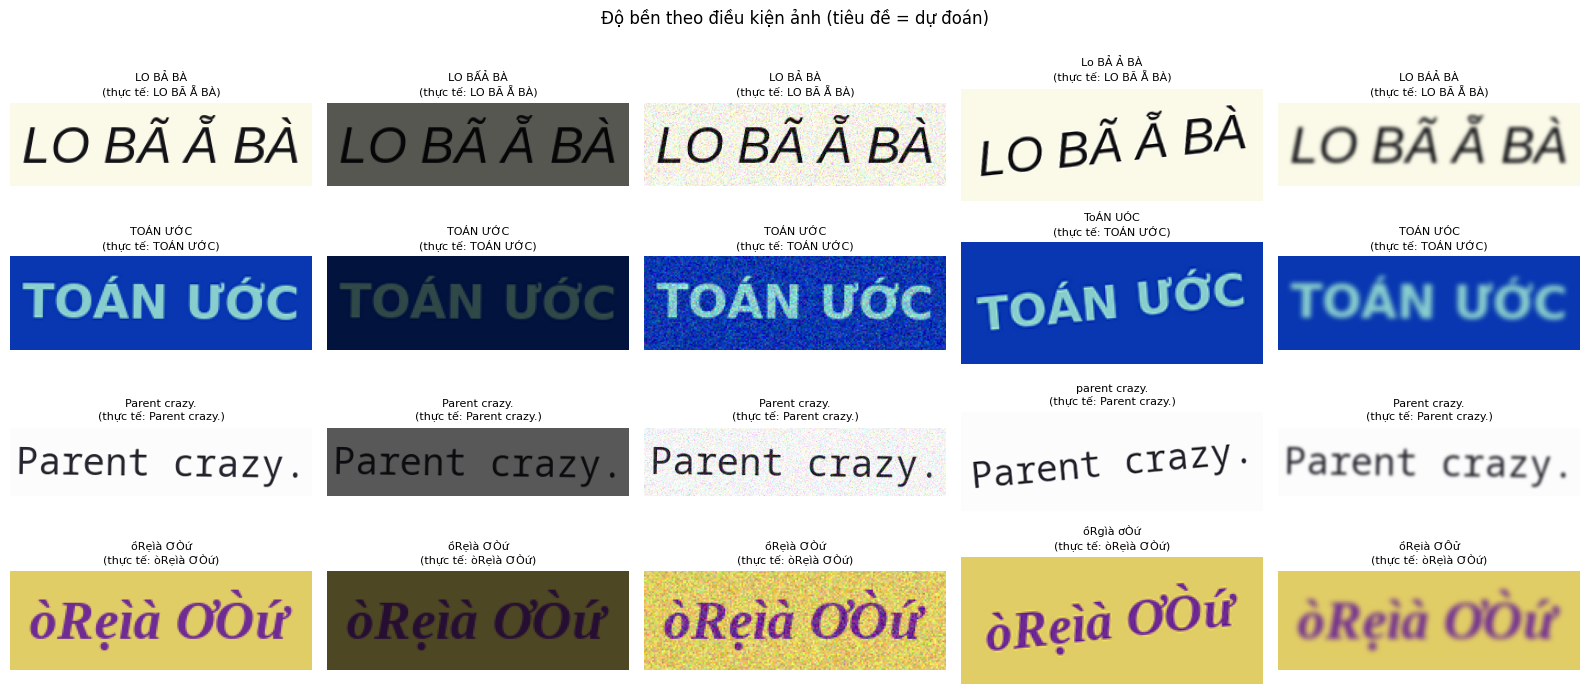

In [ ]:
@torch.no_grad()
def predict_pils(imgs, bs=64):
    # nhận danh sách ảnh PIL, trả về chuỗi dự đoán (Greedy)
    outs = []
    for s in range(0, len(imgs), bs):
        chunk = [preprocess_pil(im.convert("L")) for im in imgs[s:s + bs]]
        x, widths = pad_images([c[0] for c in chunk], [c[1] for c in chunk])
        lp = forward_logprobs(x.to(DEVICE)).cpu().numpy()
        in_len = model.input_lengths(widths)
        outs += [greedy_from_logprobs(lp[:int(in_len[b]), b]) for b in range(len(chunk))]
    return outs

def recognize_image(img, verbose=True):
    # Quy trình: ảnh gốc -> tiền xử lý -> mô hình -> Greedy -> văn bản + thời gian
    if img.height / img.width > 0.5 and verbose:
        print("Cảnh báo: ảnh có vẻ không phải MỘT dòng chữ (cao so với rộng). Mô hình chỉ huấn luyện trên ảnh một dòng.")
    sync(); t0 = time.perf_counter()
    text = predict_pils([img])[0]
    sync(); ms = (time.perf_counter() - t0) * 1000
    return text, ms

def dim(im):    return ImageEnhance.Brightness(im.convert("RGB")).enhance(0.35)
def noisy(im):
    a = np.asarray(im.convert("RGB")).astype(np.float32) + np.random.default_rng(0).normal(0, 25, (im.height, im.width, 3))
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
def tilt(im):
    bg = tuple(int(v) for v in np.median(np.asarray(im.convert("RGB"))[:, 0], axis=0))
    return im.convert("RGB").rotate(6, resample=Image.BICUBIC, expand=True, fillcolor=bg)
def blur(im):   return im.convert("RGB").filter(ImageFilter.GaussianBlur(1.5))
CONDITIONS = {"Gốc": lambda im: im.convert("RGB"), "Độ sáng thấp (x0.35)": dim, "Nhiễu (σ=25)": noisy,
              "Nghiêng 6°": tilt, "Mờ (r=1.5)": blur}

n_eval = min(300, len(test_ds))
orig_imgs = [Image.open(DATA_ROOT / p) for p in test_paths[:n_eval]]
refs_sub = test_refs[:n_eval]
rob_rows, rob_preds = [], {}
for cname, fn in CONDITIONS.items():
    preds = predict_pils([fn(im) for im in orig_imgs]); rob_preds[cname] = preds
    rob_rows.append({"Điều kiện": cname, "CER (%)": round(corpus_cer(refs_sub, preds)["CER"] * 100, 2),
                     "Word Accuracy (%)": round(word_accuracy(refs_sub, preds) * 100, 2)})
rob_table = pd.DataFrame(rob_rows); display(rob_table)

CONF = set("0O1lI5S2Z8B6Go")
VN_ACC = set("àáảãạăằắẳẵặâầấẩẫậđèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵ")
VN_ACC |= {c.upper() for c in VN_ACC}
subsets = {"Ảnh chứa ký tự dễ nhầm (0 O 1 l I 5 S...)": [i for i, t in enumerate(test_refs) if sum(c in CONF for c in t) >= 3],
           "Ảnh có >=3 ký tự tiếng Việt có dấu": [i for i, t in enumerate(test_refs) if sum(c in VN_ACC for c in t) >= 3]}
sub_rows = []
for name, ids in subsets.items():
    if ids:
        r_ = [test_refs[i] for i in ids]; p_ = [greedy_preds[i] for i in ids]
        sub_rows.append({"Nhóm con (test, Greedy)": name, "Số ảnh": len(ids), "CER (%)": round(corpus_cer(r_, p_)["CER"] * 100, 2),
                         "Word Accuracy (%)": round(word_accuracy(r_, p_) * 100, 2)})
display(pd.DataFrame(sub_rows))

fig, axes = plt.subplots(4, len(CONDITIONS), figsize=(16, 7))
for r in range(4):
    for c, (cname, fn) in enumerate(CONDITIONS.items()):
        axes[r, c].imshow(fn(orig_imgs[r])); axes[r, c].axis("off")
        axes[r, c].set_title(f"{rob_preds[cname][r]}\n(thực tế: {refs_sub[r]})" if True else "", fontsize=8)
plt.suptitle("Độ bền theo điều kiện ảnh (tiêu đề = dự đoán)", y=1.0); plt.tight_layout(); plt.show()

In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=rob_table)

https://docs.google.com/spreadsheets/d/1yG-JwkrmUpQ-5qxx1LSXZMo9auwsl9pPxMsEwC4ZfQ0/edit#gid=0


### Cell 6.4: Tải ảnh của bạn lên để nhận dạng (upload)
Chạy cell, chọn file ảnh (PNG/JPG) **chứa một dòng chữ**. Ảnh nhiều dòng/cả trang tài liệu nằm ngoài phạm vi huấn luyện, mô hình sẽ cho kết quả kém. Muốn dùng, hãy cắt từng dòng trước.

Saving 1.jpg to 1.jpg


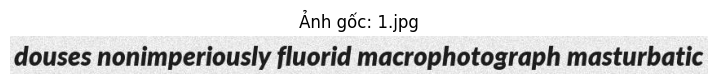

Văn bản dự đoán: 'douses nonimperiously fluorid macrophotograph magturbatic'
Thời gian dự đoán (gồm tiền xử lý): 28.3 ms


In [ ]:
def run_upload():
    from google.colab import files
    up = files.upload()
    for name, data in up.items():
        img = Image.open(__import__("io").BytesIO(data)).convert("RGB")
        text, ms = recognize_image(img)
        plt.figure(figsize=(9, 2)); plt.imshow(img); plt.axis("off"); plt.title("Ảnh gốc: " + name); plt.show()
        print(f"Văn bản dự đoán: {text!r}\nThời gian dự đoán (gồm tiền xử lý): {ms:.1f} ms")

if IN_COLAB:
    run_upload()
else:
    print("Không chạy trên Colab, bỏ qua bước upload. Thử với 1 ảnh test:")
    print(recognize_image(orig_imgs[0]), "| thực tế:", refs_sub[0])

---
# GIAI ĐOẠN 7: PHÂN TÍCH LỖI, HẠN CHẾ, KẾT LUẬN

Các cell dưới đây **tự phân loại lỗi từ kết quả thật** trên tập test. Phần nhận xét trong Markdown chỉ nêu cách đọc và gợi ý hướng xử lý; con số cụ thể lấy từ output của cell.

### Cell 7.1: Phân loại lỗi tự động (Greedy)
Quy tắc (theo thứ tự ưu tiên): dự đoán rỗng → chỉ nhầm hoa/thường → chỉ sai dấu/thanh tiếng Việt → nhầm chữ số/chữ cái → nhầm ký tự hình dạng gần giống → mất ký tự ở đầu/cuối → sai khoảng trắng → khác (nhiều lỗi kết hợp).

In [ ]:
def strip_marks(s):
    s = s.replace("đ", "d").replace("Đ", "D")
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

SIMILAR = {("O", "0"), ("0", "O"), ("l", "I"), ("I", "l"), ("l", "1"), ("1", "l"), ("I", "1"), ("1", "I"),
           ("S", "5"), ("5", "S"), ("Z", "2"), ("2", "Z"), ("B", "8"), ("8", "B"), ("G", "6"), ("6", "G"),
           ("u", "v"), ("v", "u"), ("n", "h"), ("h", "n"), ("c", "e"), ("e", "c"), ("i", "j"), ("j", "i"), ("a", "o"), ("o", "a")}

def classify_error(ref, pred):
    ref, pred = norm_eval(ref), norm_eval(pred)
    ops = align_ops(ref, pred)
    subs = [(o[1], o[2]) for o in ops if o[0] == "sub"]
    if pred == "":                                                return "Dự đoán rỗng (không nhận ra chữ)"
    if pred.casefold() == ref.casefold():                         return "Nhầm hoa/thường"
    if strip_marks(pred).casefold() == strip_marks(ref).casefold(): return "Sai dấu/thanh tiếng Việt"
    if any(r.isalnum() and h.isalnum() and r.isdigit() != h.isdigit() for r, h in subs): return "Nhầm chữ số và chữ cái"
    if any(p in SIMILAR for p in subs):                           return "Nhầm ký tự hình dạng gần giống"
    non_eq = [i for i, o in enumerate(ops) if o[0] != "eq"]
    if non_eq and all(ops[i][0] == "del" for i in non_eq) and (max(non_eq) == len(ops) - 1 or min(non_eq) == 0):
        return "Mất ký tự đầu/cuối"
    if any(" " in (o[1], o[2]) for o in ops if o[0] != "eq"):     return "Sai khoảng trắng"
    return "Khác (nhiều lỗi kết hợp)"

err_idx = [i for i in range(N_test) if norm_eval(test_refs[i]) != norm_eval(greedy_preds[i])]
print(f"Số mẫu sai (Greedy): {len(err_idx)}/{N_test} = {len(err_idx)/N_test*100:.2f}%")

err_df = pd.DataFrame({
    "Ảnh đầu vào": [test_paths[i] for i in err_idx],
    "Văn bản thực tế": [test_refs[i] for i in err_idx],
    "Văn bản dự đoán": [greedy_preds[i] for i in err_idx],
})
err_df["Loại lỗi"] = [classify_error(r, p) for r, p in zip(err_df["Văn bản thực tế"], err_df["Văn bản dự đoán"])]
err_summary = err_df["Loại lỗi"].value_counts()
display(err_summary.to_frame("Số mẫu"))
pd.set_option("display.max_colwidth", 60)
display(err_df.head(25))
err_df.to_csv(CKPT_DIR / "error_table.csv", index=False, encoding="utf-8")

Số mẫu sai (Greedy): 155/400 = 38.75%


,Số mẫu
Loại lỗi,
Sai dấu/thanh tiếng Việt,86
Khác (nhiều lỗi kết hợp),40
Nhầm hoa/thường,9
Nhầm chữ số và chữ cái,9
Sai khoảng trắng,6
Nhầm ký tự hình dạng gần giống,5


,Ảnh đầu vào,Văn bản thực tế,Văn bản dự đoán,Loại lỗi
0,test/images/002400.png,LO BÃ Ẵ BÀ,LO BẢ BÀ,Sai khoảng trắng
1,test/images/002403.png,òRẹìà ƠÒứ,ồRẹìà ƠÒứ,Sai dấu/thanh tiếng Việt
2,test/images/002408.png,TÍNH MÔI MỖI NẮNG NGẮN,TÍMH MÔI MỐI NẢNG NGN,Khác (nhiều lỗi kết hợp)
3,test/images/002409.png,Trí tuệ nhân tạo,Tri tuệ nhân tạo,Sai dấu/thanh tiếng Việt
4,test/images/002413.png,vu20@vu.vn,Vu20@wu.vn,Khác (nhiều lỗi kết hợp)
5,test/images/002414.png,XÂY TẬP HIỆN NAM,XY TẬP HIỆN NAM,Khác (nhiều lỗi kết hợp)
6,test/images/002415.png,tỡ nỉ nỹ kở,tố nỉ nỹ kở,Sai dấu/thanh tiếng Việt
7,test/images/002416.png,Lớp 11C2,Lớp llC2,Nhầm chữ số và chữ cái
8,test/images/002417.png,nẸẳằỵỢÉỆỏÈ,nẸẵâyỢ ÉỆỏÈ,Sai khoảng trắng
9,test/images/002419.png,AN ĐỊNH,AN ĐJNH,Khác (nhiều lỗi kết hợp)


### Cell 7.2: Cặp ký tự hay bị nhầm nhất, lỗi theo độ dài nhãn, và ảnh hưởng của độ nét/độ tương phản

In [ ]:
conf = Counter()
for i in range(N_test):
    for tag, r, h in align_ops(norm_eval(test_refs[i]), norm_eval(greedy_preds[i])):
        if tag == "sub": conf[(r, h)] += 1
        elif tag == "del": conf[(r, "∅")] += 1
        elif tag == "ins": conf[("∅", h)] += 1
print("Top 15 cặp (thực tế -> dự đoán) bị nhầm; ∅ = thiếu/thừa ký tự:")
for (r, h), c in conf.most_common(15): print(f"   {r!r} -> {h!r}: {c}")

# lỗi theo độ dài nhãn
lens = np.array([len(norm_eval(t)) for t in test_refs]); wrong = np.zeros(N_test, bool); wrong[err_idx] = True
bins = [(1, 5), (6, 10), (11, 20), (21, 40)]
print("\nTỷ lệ mẫu sai theo độ dài nhãn:")
for lo, hi in bins:
    m = (lens >= lo) & (lens <= hi)
    if m.any(): print(f"   {lo:2d}-{hi:2d} ký tự: {wrong[m].mean()*100:5.1f}% sai ({m.sum()} mẫu)")

# độ nét (phương sai Laplacian) và độ tương phản (độ lệch chuẩn) của ảnh đúng vs sai
def sharp_contrast(path):
    a = np.asarray(Image.open(DATA_ROOT / path).convert("L"), dtype=np.float32)
    lap = 4 * a[1:-1, 1:-1] - a[:-2, 1:-1] - a[2:, 1:-1] - a[1:-1, :-2] - a[1:-1, 2:]
    return lap.var(), a.std()
sc = np.array([sharp_contrast(p) for p in test_paths])
for name, m in [("Đúng", ~wrong), ("Sai", wrong)]:
    if m.any(): print(f"   Ảnh {name:4s}: độ nét (Laplacian var) trung vị = {np.median(sc[m,0]):8.1f} | độ tương phản (std) trung vị = {np.median(sc[m,1]):6.1f} | n={m.sum()}")

Top 15 cặp (thực tế -> dự đoán) bị nhầm; ∅ = thiếu/thừa ký tự:
   ' ' -> '∅': 5
   'I' -> 'l': 5
   '1' -> 'l': 4
   'ế' -> 'ể': 4
   'Ỉ' -> 'Ĩ': 4
   'Ế' -> 'Ể': 4
   'ầ' -> 'à': 4
   'ò' -> 'ồ': 3
   'ỵ' -> 'y': 3
   'ữ' -> 'ử': 3
   'f' -> '∅': 3
   'ồ' -> 'ô': 3
   'S' -> 's': 3
   'ằ' -> 'ẳ': 3
   'ỉ' -> 'i': 3

Tỷ lệ mẫu sai theo độ dài nhãn:
    1- 5 ký tự:  33.9% sai (56 mẫu)
    6-10 ký tự:  37.2% sai (129 mẫu)
   11-20 ký tự:  43.3% sai (120 mẫu)
   21-40 ký tự:  37.9% sai (95 mẫu)
   Ảnh Đúng: độ nét (Laplacian var) trung vị =   2281.6 | độ tương phản (std) trung vị =   50.0 | n=245
   Ảnh Sai : độ nét (Laplacian var) trung vị =   2018.3 | độ tương phản (std) trung vị =   47.8 | n=155


### Cell 7.3: Ví dụ nhận dạng đúng và sai bằng hình ảnh

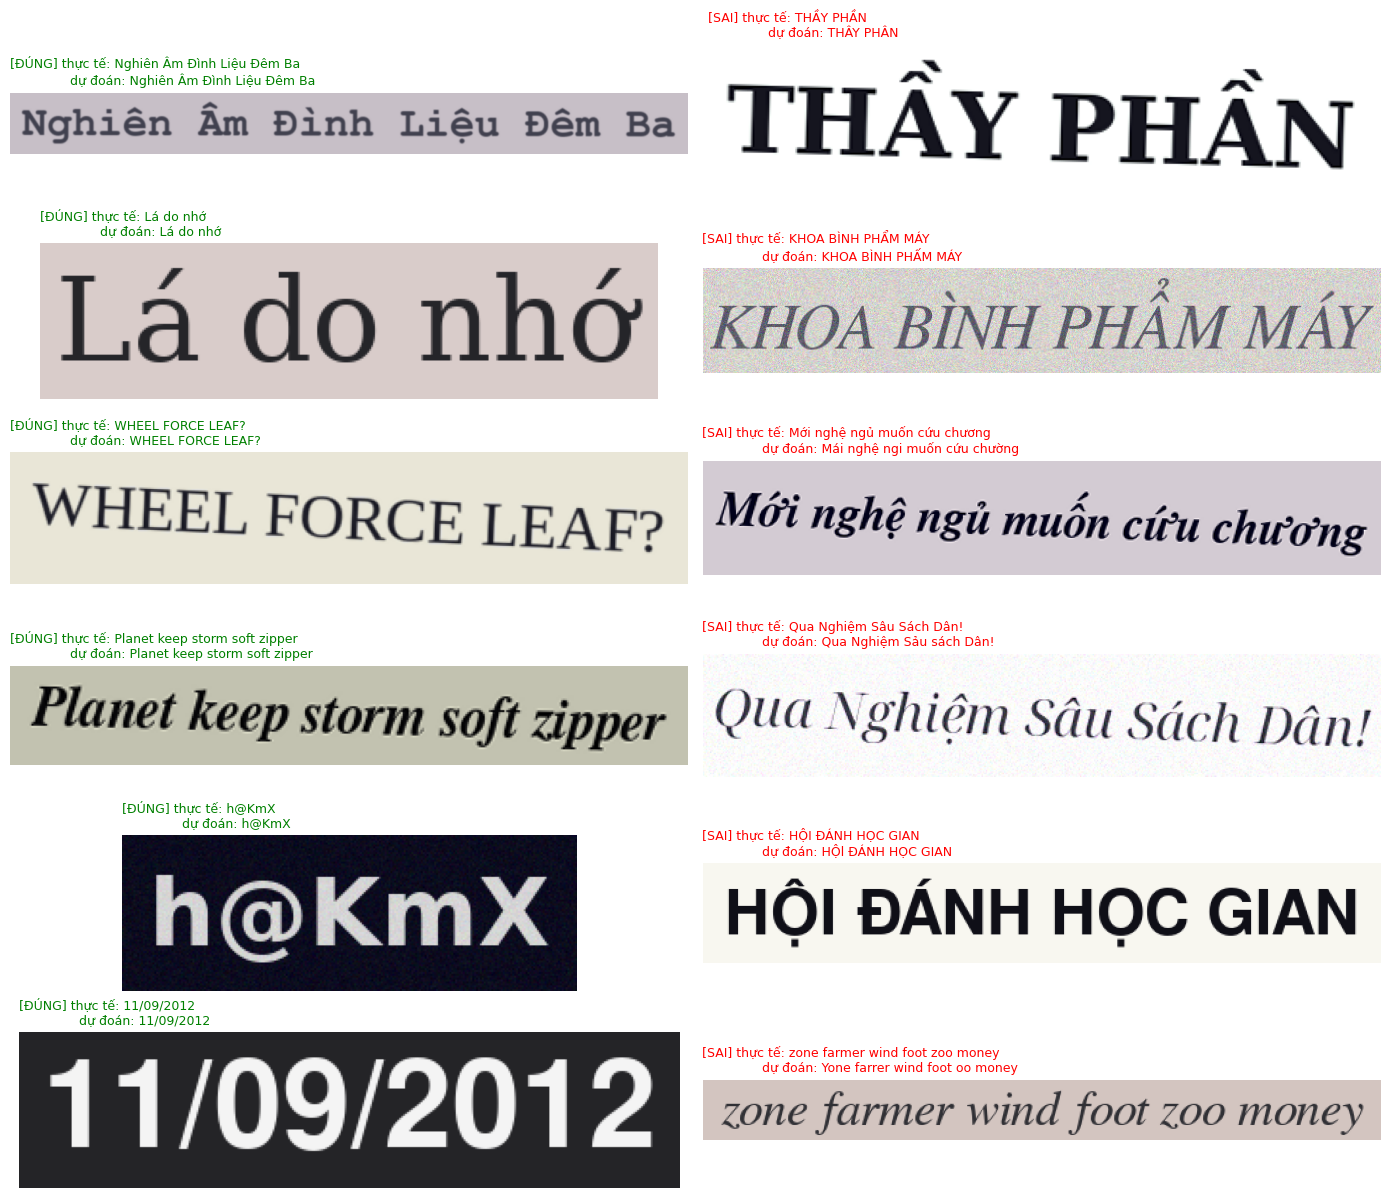

In [ ]:
rng = random.Random(0)
ok_idx = [i for i in range(N_test) if not wrong[i]]
show_ok = rng.sample(ok_idx, min(6, len(ok_idx)))
show_bad = rng.sample(err_idx, min(6, len(err_idx))) if err_idx else []
fig, axes = plt.subplots(max(len(show_ok), len(show_bad), 1), 2, figsize=(14, 2.0 * max(len(show_ok), len(show_bad), 1)))
axes = np.atleast_2d(axes)
for col, (title, ids, colr) in enumerate([("ĐÚNG", show_ok, "green"), ("SAI", show_bad, "red")]):
    for r in range(axes.shape[0]):
        ax = axes[r, col]; ax.axis("off")
        if r < len(ids):
            i = ids[r]; ax.imshow(Image.open(DATA_ROOT / test_paths[i]))
            ax.set_title(f"[{title}] thực tế: {test_refs[i]}\n               dự đoán: {greedy_preds[i]}", fontsize=9, loc="left", color=colr)
plt.tight_layout(); plt.show()

### Cách đọc kết quả phân tích lỗi và hướng cải thiện
Đối chiếu với số liệu ở Cell 7.1 và 7.2, rồi áp dụng theo nhóm lỗi chiếm nhiều nhất:

| Nhóm lỗi nổi bật | Nguyên nhân thường gặp | Hướng cải thiện |
|---|---|---|
| Sai dấu/thanh tiếng Việt | Dấu nhỏ, nằm ở mép trên/dưới; chiều cao 48 px làm dấu chỉ còn vài pixel; ảnh mờ làm mất dấu | Tăng `IMG_H` (64), thêm dữ liệu chữ có dấu, giảm blur/nhiễu quá mức khi sinh dữ liệu |
| Nhầm chữ số/chữ cái, ký tự gần giống (`0/O`, `l/I/1`) | Hình dạng gần như trùng nhau; **không có ngữ cảnh** để phân biệt (chuỗi ký tự ngẫu nhiên) | Thêm mô hình ngôn ngữ/từ điển khi giải mã; thêm dữ liệu có ngữ cảnh |
| Nhầm hoa/thường | Cặp như `c/C`, `o/O`, `s/S`, `v/V`, `z/Z` có hình giống nhau, khác kích thước tương đối | Ảnh có kích thước chữ đa dạng hơn, nhiều dữ liệu hơn |
| Mất ký tự đầu/cuối | Lề ảnh quá sát; ký tự hẹp bị CNN nuốt | Đảm bảo lề tối thiểu, tăng số bước thời gian `T` |
| Sai khoảng trắng | Khoảng cách giữa ký tự không đều, dấu cách hẹp/rộng | Augmentation giãn chữ, font có spacing khác nhau |
| Ảnh mờ/nhiễu | So sánh độ nét và độ tương phản giữa nhóm đúng và sai ở Cell 7.2 | Tăng cường mức nhiễu/mờ khi train |
| Ký tự/từ chưa thấy khi huấn luyện | CTC không có kiến thức ngôn ngữ; dataset này lấy từ vựng giới hạn | Mở rộng kho từ vựng, dùng văn bản thật (báo, sách) để sinh ảnh |

### Cell 7.4: Tạo báo cáo thực nghiệm tự động (số liệu lấy từ biến thật)

In [ ]:
def df_to_text(d):
    try:
        return d.to_markdown(index=False)
    except Exception:                      # thiếu thư viện tabulate
        return d.to_string(index=False)

best_row = hist.loc[hist.val_cer.idxmin()]
lines = []
lines.append("# BÁO CÁO THỰC NGHIỆM: CRNN + BiLSTM + CTC (nhận dạng chữ tiếng Việt)\n")
lines.append(f"- Chế độ dữ liệu: `{MODE}` | train/val/test = {len(train_ds)}/{len(val_ds)}/{len(test_ds)} ảnh")
lines.append(f"- Kiến trúc: CNN (7 conv + BN) -> BiLSTM 2 tầng (hidden 256) -> Linear({NUM_CLASSES} lớp, gồm BLANK) | {n_params/1e6:.2f} M tham số")
lines.append(f"- Ảnh vào: xám, cao {IMG_H}px, giữ tỷ lệ, T = W/2")
lines.append(f"- Huấn luyện: AdamW lr={LR}, OneCycleLR, batch {BATCH_SIZE}, AMP={USE_AMP}, {len(hist)}/{EPOCHS} epoch")
lines.append(f"- Epoch tốt nhất: {int(best_row.epoch)} (val CER {best_row.val_cer*100:.2f}%, val loss {best_row.val_loss:.4f})")
lines.append(f"- Test CTC loss: {test_loss:.4f}\n")
lines.append("## Kết quả trên tập test\n")
lines.append(df_to_text(table))
lines.append("\n## Độ bền theo điều kiện ảnh (300 ảnh test đầu, Greedy)\n")
lines.append(df_to_text(rob_table))
lines.append("\n## Phân loại lỗi (Greedy)\n")
lines.append(f"Tổng mẫu sai: {len(err_idx)}/{N_test}\n")
for k, v in err_summary.items(): lines.append(f"- {k}: {v}")
report = "\n".join(lines)
(PROJECT_ROOT / f"BAO_CAO_{RUN_NAME}.md").write_text(report, encoding="utf-8")
print(report)

# BÁO CÁO THỰC NGHIỆM: CRNN + BiLSTM + CTC (nhận dạng chữ tiếng Việt)

- Chế độ dữ liệu: `small` | train/val/test = 2000/400/400 ảnh
- Kiến trúc: CNN (7 conv + BN) -> BiLSTM 2 tầng (hidden 256) -> Linear(215 lớp, gồm BLANK) | 8.55 M tham số
- Ảnh vào: xám, cao 48px, giữ tỷ lệ, T = W/2
- Huấn luyện: AdamW lr=0.001, OneCycleLR, batch 64, AMP=True, 40/40 epoch
- Epoch tốt nhất: 39 (val CER 4.61%, val loss 0.2401)
- Test CTC loss: 0.2349

## Kết quả trên tập test

| Phương pháp               |   CER (%) |   Word Accuracy (%) |   Thời gian dự đoán (ms/ảnh) |   trong đó giải mã (ms/ảnh) |
|:--------------------------|----------:|--------------------:|-----------------------------:|----------------------------:|
| CRNN + Greedy             |      5.02 |               61.25 |                         5.73 |                        0.04 |
| CRNN + Beam Search (w=10) |      4.98 |               61.5  |                         9.96 |                        4.27 |

## Độ bền theo điều kiện ảnh (300 

In [ ]:
# ===== BIỂU ĐỒ BỔ SUNG (chạy SAU Cell 7.4, cần các biến từ Cell 5.3, 6.2, 7.1, 7.2) =====
plt.rcParams["font.family"] = "DejaVu Sans"
def lab(c):                                   # nhãn dễ đọc cho khoảng trắng / thiếu-thừa
    return "␣" if c == " " else c

# ---------- Hình A: (1) Greedy vs Beam  (2) số lỗi theo loại ----------
names = [n.replace("CRNN + ", "") for n in res.keys()]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
cer_vals = [v["CER"] for v in res.values()]
ax[0].bar(names, cer_vals, color=["tab:blue", "tab:orange"][:len(names)])
ax[0].set_title("CER trên tập test (%)"); ax[0].set_ylabel("CER (%)")
for i, v in enumerate(cer_vals): ax[0].text(i, v, f"{v:.2f}", ha="center", va="bottom")
ms_vals = [v["ms_per_img"] for v in res.values()]
ax[1].bar(names, ms_vals, color=["tab:blue", "tab:orange"][:len(names)])
ax[1].set_title("Thời gian dự đoán (ms/ảnh)"); ax[1].set_ylabel("ms/ảnh")
for i, v in enumerate(ms_vals): ax[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
if len(err_summary) > 0:
    es = err_summary.sort_values()
    ax[2].barh(list(es.index), list(es.values), color="tab:red")
    for i, v in enumerate(es.values): ax[2].text(v, i, f" {v}", va="center")
    ax[2].set_title("Số mẫu sai theo loại lỗi (Greedy)"); ax[2].set_xlabel("số mẫu")
else:
    ax[2].text(0.5, 0.5, "Không có mẫu sai", ha="center", va="center"); ax[2].axis("off")
plt.tight_layout(); plt.savefig(CKPT_DIR / "chart_A_decoder_errors.png", dpi=130); plt.show()

# ---------- Hình B: (3) ma trận nhầm lẫn ký tự (heatmap) ----------
TOPK = 12
if len(conf) > 0:
    ref_tot, pred_tot = Counter(), Counter()
    for (r, h), c in conf.items():
        ref_tot[r] += c; pred_tot[h] += c
    refs_top = [c for c, _ in ref_tot.most_common(TOPK)]
    preds_top = [c for c, _ in pred_tot.most_common(TOPK)]
    M = np.array([[conf.get((r, h), 0) for h in preds_top] for r in refs_top])
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(M, cmap="Reds")
    ax.set_xticks(range(len(preds_top))); ax.set_xticklabels([lab(c) for c in preds_top], fontsize=12)
    ax.set_yticks(range(len(refs_top)));  ax.set_yticklabels([lab(c) for c in refs_top], fontsize=12)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if M[i, j] > 0:
                ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=9,
                        color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xlabel("Ký tự dự đoán (∅ = thiếu ký tự)"); ax.set_ylabel("Ký tự thực tế (∅ = thừa ký tự)")
    ax.set_title(f"Ma trận nhầm lẫn: {len(refs_top)} ký tự thực tế x {len(preds_top)} ký tự dự đoán hay gặp nhất")
    plt.colorbar(im, ax=ax, label="số lần"); plt.tight_layout()
    plt.savefig(CKPT_DIR / "chart_B_confusion.png", dpi=130); plt.show()
else:
    print("Không có lỗi ký tự nào để vẽ ma trận nhầm lẫn.")

# ---------- Hình C: (4) CER theo độ dài nhãn  (5) learning rate theo epoch ----------
bins = [(1, 5), (6, 10), (11, 20), (21, 40)]
labels_b, cer_b, n_b = [], [], []
for lo, hi in bins:
    ids = [i for i in range(N_test) if lo <= len(norm_eval(test_refs[i])) <= hi]
    if ids:
        labels_b.append(f"{lo}-{hi}\n(n={len(ids)})")
        cer_b.append(corpus_cer([test_refs[i] for i in ids], [greedy_preds[i] for i in ids])["CER"] * 100)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(labels_b, cer_b, color="tab:green")
for i, v in enumerate(cer_b): ax[0].text(i, v, f"{v:.1f}", ha="center", va="bottom")
ax[0].set_title("CER theo độ dài nhãn (Greedy)"); ax[0].set_xlabel("số ký tự của nhãn"); ax[0].set_ylabel("CER (%)")
ax[1].plot(hist["epoch"], hist["lr"], "o-", color="tab:purple")
ax[1].set_title("Learning rate theo epoch (OneCycleLR)"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("lr"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(CKPT_DIR / "chart_C_length_lr.png", dpi=130); plt.show()

### Cell 7.5 (tham khảo, không chạy): CRNN so với PARSeq, TrOCR, VietOCR
Phần này là so sánh **kiến trúc**; dự án **không** dùng kết quả benchmark của các mô hình đó làm kết quả của mình.

| | CRNN + CTC (mô hình của dự án) | PARSeq | TrOCR | VietOCR |
|---|---|---|---|---|
| Ý tưởng | CNN trích đặc trưng, BiLSTM mô hình chuỗi, CTC căn chỉnh tự động | Bộ mã hóa ViT + bộ giải mã dùng ngữ cảnh (huấn luyện theo hoán vị thứ tự giải mã) | Bộ mã hóa ảnh Transformer + bộ giải mã văn bản Transformer, khởi tạo từ mô hình tiền huấn luyện | Thư viện OCR tiếng Việt: backbone CNN + Transformer hoặc Seq2Seq có attention, có trọng số huấn luyện sẵn cho tiếng Việt |
| Giải mã | Song song theo từng bước thời gian, các ký tự **độc lập có điều kiện** | Có ngữ cảnh ngôn ngữ giữa các ký tự | Tự hồi quy (sinh từng token) | Tự hồi quy |
| Ưu điểm | Nhỏ, nhanh, dễ giải thích, huấn luyện từ đầu được trên Colab | Chính xác cao, tận dụng ngữ cảnh | Mạnh, tận dụng tiền huấn luyện lớn | Sẵn sàng cho tiếng Việt |
| Hạn chế | Không có hiểu biết ngôn ngữ; dễ nhầm ký tự giống nhau khi thiếu ngữ cảnh | Nặng hơn | Nặng, cần tài nguyên | Phụ thuộc dữ liệu/phiên bản đã huấn luyện |

**Đề xuất đối chiếu (nếu có thời gian):** chạy VietOCR hoặc TrOCR trên **đúng tập test** của dự án rồi báo cáo ở một bảng riêng, tách biệt với bảng CRNN tự xây dựng.

### Hạn chế của dự án
1. Dữ liệu **tổng hợp**: từ vựng giới hạn (~300 âm tiết), font hệ thống; chưa phản ánh chữ viết tay, ảnh chụp ngoài đời thực, nền phức tạp.
2. Chỉ nhận dạng **một dòng chữ**; ảnh nhiều dòng hay cả trang tài liệu cần tách dòng trước.
3. CTC giả định các bước độc lập có điều kiện và không có mô hình ngôn ngữ, nên khó phân biệt ký tự giống nhau khi thiếu ngữ cảnh.
4. Chiều cao cố định 48 px có thể làm mất dấu rất nhỏ.
5. Beam Search ở đây không dùng mô hình ngôn ngữ nên lợi ích so với Greedy thường nhỏ.

### Hướng phát triển
- Dùng văn bản tiếng Việt thật (báo, sách, Wikipedia) để sinh dữ liệu, tăng lên 50.000+ ảnh.
- Thêm mô hình ngôn ngữ (n-gram hoặc từ điển) vào Beam Search.
- Thử `IMG_H = 64`, backbone ResNet, hoặc attention thay BiLSTM.
- Bổ sung bộ tách dòng (text detection) để xử lý ảnh tài liệu.
- Kiểm thử trên ảnh thật chụp bằng điện thoại và chữ viết tay.

### Cell 7.6: Cách dùng lại mô hình đã huấn luyện (phiên Colab mới)
Cách đơn giản nhất: mở lại notebook này và **Run all**. Giai đoạn 1 khôi phục dataset từ Drive, Giai đoạn 5 phát hiện checkpoint đã hoàn tất nên bỏ qua huấn luyện, Giai đoạn 6 nạp `best.pt`. Cell dưới nạp lại `best.pt` và nhận dạng một ảnh.

In [ ]:
def load_trained_model(path=BEST):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    assert ck["charset"] == CHARSET, "Charset của checkpoint khác charset hiện tại!"
    m = CRNN(**ck["cfg"]).to(DEVICE); m.load_state_dict(ck["model"]); m.eval()
    return m

model = load_trained_model()
img = Image.open(DATA_ROOT / test_paths[0]).convert("RGB")
print("Dự đoán:", recognize_image(img), "| thực tế:", test_refs[0])

Dự đoán: ('LO B Ả BÀ', 9.448156999951607) | thực tế: LO BÃ Ẵ BÀ
